# Complaint Triage Intelligence

## Complaint Triage Intelligence
### Türkçe Müşteri Geri Bildirimlerinde Otomatik Şikâyet Tespiti ve Açıklanabilir NLP Model Karşılaştırması


**Veri Seti Adı:** Complaint Classification Dataset  
**Veri Seti Sağlayıcısı:** nanelimon (Nane&Limon)  
**Veri Seti Bağlantısı:** https://huggingface.co/datasets/nanelimon/complaint-classification-dataset  
**Veri Seti Lisansı:** Apache License 2.0 (Apache-2.0)  
**Veri Seti Dili:** Türkçe

### Problem Tanımı

Bu çalışmada, Türkçe müşteri geri bildirimlerinin şikâyet içeren ve şikâyet içermeyen metinler olarak otomatik sınıflandırılması amaçlanmaktadır. Metinler üzerinde Türkçe doğal dil işleme, dilbilimsel analiz ve farklı metin temsil yöntemleri uygulanarak geleneksel makine öğrenmesi modelleri ile BERTurk tabanlı bağlamsal temsillerin performansları karşılaştırılacaktır. Elde edilen sonuçlar doğruluk, Macro F1 ve hata analizleriyle değerlendirilerek müşteri hizmetleri süreçlerinde otomatik şikâyet tespitinin uygulanabilirliği incelenecektir.

In [1]:

# ============================================================
# BİL482 - ÖDEV 1
# G1-G7: Gerekli Kütüphanelerin Kurulumu ve Rastgelelik Ayarları
# ============================================================

# Google Colab'da ödev boyunca kullanılacak ve varsayılan
# ortamda bulunması garanti olmayan kütüphaneleri kuruyoruz.
# NumPy, Pandas, Matplotlib, Scikit-learn ve PyTorch gibi
# Colab'da hazır bulunan paketleri yeniden kurmuyoruz.

%pip -q install "datasets==4.8.5" "stanza==1.15.0" "gensim==4.4.0" "wordcloud>=1.9,<2" "transformers==4.57.6" "sentencepiece>=0.2,<1"

# Deneylerde kullanılacak ortak rastgelelik değeri.
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# GPU varsa PyTorch için de rastgelelik sabitlenir.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# BERTurk işlemlerinde kullanılacak cihaz belirlenir.
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Kurulum tamamlandı.")
print("Random seed:", SEED)
print("Çalışma cihazı:", DEVICE)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
Kurulum tamamlandı.
Random seed: 42
Çalışma cihazı: cpu


## G1 — Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

In [2]:

# G1.1 - Veri setinin yüklenmesi ve ilk inceleme
# Hugging Face üzerindeki Türkçe şikâyet veri seti yüklenir.
# Veri boyutu, sütunlar, eksik değerler ve etiketler incelenir.

from datasets import load_dataset
import pandas as pd

DATASET_ID = "nanelimon/complaint-classification-dataset"

# Veri setini doğrudan Hugging Face üzerinden yükle.
dataset = load_dataset(DATASET_ID, split="train")
df_raw = dataset.to_pandas()

# Sütun isimlerini standartlaştır.
df = df_raw.rename(columns={"Text": "text", "Label": "label"}).copy()

# Beklenen sütunların bulunduğunu doğrula.
assert {"text", "label"}.issubset(df.columns)

print("Toplam kayıt:", len(df))
print("Sütunlar:", df.columns.tolist())

print("\nİlk 5 kayıt:")
display(df.head())

print("\nEksik değerler:")
print(df[["text", "label"]].isna().sum())

print("\nEtiket dağılımı:")
print(df["label"].value_counts().sort_index())

print("\nTekrarlanan metin sayısı:")
print(df["text"].duplicated().sum())


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Comments.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/6914 [00:00<?, ? examples/s]

Toplam kayıt: 6914
Sütunlar: ['text', 'label']

İlk 5 kayıt:


,text,label
0,"""Kombi kronik arızalı"" devreye girerken şiddet...",1.0
1,#Dürüst yorum#hoş güzel sevdim ama nasıl yıkic...,0.0
2,#Oslobet @Oslobet 2000 TL yatırım yaptım 2837 ...,1.0
3,#payco Telefon numarası güncelleme işlemimi ta...,1.0
4,(44 EU 222) 2024/8/11 saat 12:30 öğlen bu arab...,1.0



Eksik değerler:
text     0
label    0
dtype: int64

Etiket dağılımı:
label
0.0    4309
1.0    2605
Name: count, dtype: int64

Tekrarlanan metin sayısı:
4


Başlangıç kayıt sayısı: 6914
Çelişkili etiketli metin sayısı: 4
Çelişkili etiketli kayıt sayısı: 8
Toplam çıkarılan kayıt: 8
Temiz kayıt sayısı: 6906

Sınıf dağılımı:
label
0    4305
1    2601
Name: count, dtype: int64

Sınıf yüzdeleri (%):
label
0    62.34
1    37.66
Name: proportion, dtype: float64

Metin uzunluğu istatistikleri:


,char_count,word_count
count,6906.00,6906.00
mean,161.15,22.51
std,245.63,33.02
min,1.00,1.00
25%,30.00,5.00
50%,58.00,9.00
75%,233.00,32.00
max,2513.00,367.00



Sınıflara göre kelime sayısı:


,count,mean,median,std,max
label,,,,,
0,4305,8.02,6.0,6.63,60
1,2601,46.50,38.0,43.58,367


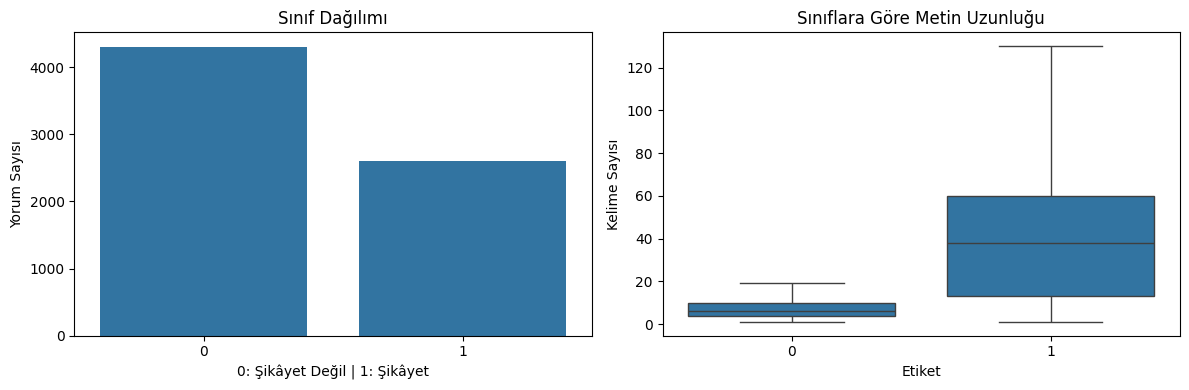

In [3]:

# ============================================================
# G1.2 - Veri Temizliği ve Keşifsel Veri Analizi (EDA)
# ============================================================
# Çelişkili etiketler ve tekrarlar temizlenir.
# Sınıf dağılımı ile metin uzunlukları analiz edilir.

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Orijinal veri üzerinden temiz bir kopya oluştur.
df = df_raw.rename(columns={"Text": "text", "Label": "label"}).copy()

# 2. Eksik ve boş metinleri kaldır.
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 0].copy()

# 3. Etiketleri kontrol et ve tam sayıya dönüştür.
assert df["label"].isin([0, 1]).all()
df["label"] = df["label"].astype(int)

# 4. Aynı metnin farklı etiketlerle işaretlendiği
# kayıtları belirle ve tamamını çıkar.
label_counts = df.groupby("text")["label"].nunique()
conflicting_texts = label_counts[label_counts > 1].index
conflict_records = df["text"].isin(conflicting_texts).sum()

df = df[~df["text"].isin(conflicting_texts)].copy()

# 5. Aynı etiketli tekrarlanan metinleri kaldır.
df = df.drop_duplicates(subset="text").reset_index(drop=True)

# 6. Metin uzunluğu özelliklerini oluştur.
df["char_count"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

# 7. Temiz veri bütünlüğünü doğrula.
assert not df["text"].duplicated().any()
assert df["label"].isin([0, 1]).all()

# 8. Temizleme sonuçlarını göster.
print("Başlangıç kayıt sayısı:", len(df_raw))
print("Çelişkili etiketli metin sayısı:", len(conflicting_texts))
print("Çelişkili etiketli kayıt sayısı:", conflict_records)
print("Toplam çıkarılan kayıt:", len(df_raw) - len(df))
print("Temiz kayıt sayısı:", len(df))

print("\nSınıf dağılımı:")
print(df["label"].value_counts().sort_index())

print("\nSınıf yüzdeleri (%):")
print(
    (df["label"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# 9. Metin uzunluklarının özet istatistiklerini göster.
print("\nMetin uzunluğu istatistikleri:")
display(df[["char_count", "word_count"]].describe().round(2))

print("\nSınıflara göre kelime sayısı:")
display(
    df.groupby("label")["word_count"]
    .agg(["count", "mean", "median", "std", "max"])
    .round(2)
)

# 10. Sınıf dağılımını görselleştir.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df, x="label",
    order=[0, 1],
    ax=axes[0]
)
axes[0].set_title("Sınıf Dağılımı")
axes[0].set_xlabel("0: Şikâyet Değil | 1: Şikâyet")
axes[0].set_ylabel("Yorum Sayısı")

# 11. Metin uzunluğu dağılımını görselleştir.
sns.boxplot(
    data=df, x="label", y="word_count",
    order=[0, 1],
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Sınıflara Göre Metin Uzunluğu")
axes[1].set_xlabel("Etiket")
axes[1].set_ylabel("Kelime Sayısı")

plt.tight_layout()
plt.show()


### G1 — Değerlendirme ve Bulgular

Bu aşamada Hugging Face üzerinden elde edilen 6.914 Türkçe müşteri geri bildirimi incelenmiştir. Veri setinde eksik değer bulunmamış, ancak aynı metnin farklı sınıflarla etiketlendiği 4 çelişkili metin (8 kayıt) tespit edilmiştir. Etiket tutarsızlığını ve olası veri sızıntısını azaltmak amacıyla bu kayıtlar çıkarılmış, analizler 6.906 benzersiz metin üzerinden sürdürülmüştür.

Temiz veri setinin %62,34'ü şikâyet içermeyen (0), %37,66'sı şikâyet içeren (1) yorumlardan oluşmaktadır. Bu dağılım sınıflar arasında belirli bir dengesizlik olduğunu göstermektedir. Bu nedenle sonraki sınıflandırma aşamasında yalnızca Accuracy değil, sınıfları eşit ağırlıklandıran Macro F1 metriği de kullanılacaktır.

Metin uzunluğu analizinde yorumların ortalama 22,51, medyan 9 kelime içerdiği görülmüştür. Şikâyet içermeyen yorumların ortalama uzunluğu 8,02 kelime iken şikâyet içeren yorumlarda bu değer 46,50 kelimedir. Şikâyet metinlerinin yaklaşık 5,8 kat uzun olması, metin uzunluğunun sınıflarla ilişkili olabileceğini göstermektedir. Ancak bu farkın veri kaynakları veya yorum türlerinden etkilenmiş olabileceği unutulmamalıdır.

**Sınırlılıklar:** Veri setinin farklı kaynaklardan derlenmiş olması, modellerin gerçek şikâyet ifadeleri yerine kaynaklara özgü dil kalıplarını öğrenmesine neden olabilir. Ayrıca sınıflar arasındaki uzunluk farkı, yüksek sınıflandırma başarısının tek başına anlamsal şikâyet tespitini kanıtlamayacağını göstermektedir. Bu etkiler sonraki model değerlendirme ve hata analizi aşamalarında dikkate alınacaktır.

## G2 — Türkçe Metin Ön İşleme

Bu bölümde Türkçeye özgü küçük harfe dönüştürme, tokenizasyon ve stopword temizleme işlemleri uygulanacaktır. Ayrıca 15 Türkçe kelime üzerinde stemming (gövdeleme) ve lemmatization (sözlük biçimine indirgeme) yöntemleri karşılaştırılacaktır.

In [4]:

# ============================================================
# G2 - Türkçe Metin Ön İşleme ve Morfolojik Analiz
# ============================================================
# Türkçeye uygun küçük harfe dönüştürme, tokenizasyon,
# stopword temizleme, stemming ve lemmatization uygulanır.

import re
import stanza
from nltk.stem.snowball import SnowballStemmer
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)

# 1. Türkçeye özgü küçük harfe dönüştürme.
# Python'un standart lower() işlemi I/İ harflerinde
# Türkçe dil kurallarını her zaman doğru uygulamaz.
def turkish_lower(text):
    return str(text).replace("I", "ı").replace("İ", "i").lower()

# 2. Türkçe karakterleri koruyan tokenizasyon.
# Noktalama işaretleri ayrıştırılır; yalnızca kelimeler alınır.
def tokenize_tr(text):
    return re.findall(
        r"[a-zçğıöşü]+",
        turkish_lower(text)
    )

# 3. Şikâyet anlamını etkileyen olumsuzluk ve karşıtlık
# ifadeleri (değil, yok, ama, fakat vb.) korunur.
stopwords_tr = set(stopwords.words("turkish")) | {
    "olarak", "olan", "gibi"
}
# Olumsuzluk ve karşıtlık ifadeleri sınıflandırmada anlam taşır.
stopwords_tr -= {"değil", "yok", "ama", "fakat", "hayır", "hiç"}

def sentence_tokenize_tr(text):
    """Basit kural tabanlı Türkçe cümle segmentasyonu."""
    return [x.strip() for x in re.split(r"(?<=[.!?])\s+", str(text)) if x.strip()]

def on_isle(metin):
    """Ödevde istenen tek girişli ön işleme arayüzü."""
    return preprocess_tr(metin)

print("Cümle tokenization örneği:", sentence_tokenize_tr(
    "Ürün geldi. Ancak kutu hasarlıydı! İade istiyorum."))
print("I/İ dönüşümü:", turkish_lower("IĞDIR İSTANBUL"))

# 4. Ön işleme fonksiyonu.
def preprocess_tr(text):
    tokens = tokenize_tr(text)
    return [token for token in tokens if token not in stopwords_tr]

# 5. Örnek metin üzerinde işlemleri göster.
sample_text = (
    "Ürün çok güzel görünüyordu ama teslimat gecikti "
    "ve müşteri hizmetleri sorunumu çözmedi."
)

print("Orijinal metin:")
print(sample_text)

print("\nKüçük harf:")
print(turkish_lower(sample_text))

print("\nTokenizasyon:")
print(tokenize_tr(sample_text))

print("\nStopword sonrası:")
print(preprocess_tr(sample_text))

# 6. Veri setindeki tüm yorumlara ön işleme uygula.
df["tokens"] = df["text"].apply(on_isle)
print("Öncesi/sonrası üç örnek:")
for original in df["text"].head(3):
    print("ÖNCE:", original[:160], "\nSONRA:", on_isle(original), "\n")

print("\nÖn işleme uygulanan yorum sayısı:", len(df))

# 7. Türkçe Stanza modellerini indir ve bir kez yükle.
# Morfolojik analiz için tokenize, POS ve lemma kullanılır.
stanza.download(
    "tr",
    processors="tokenize,pos,lemma",
    verbose=False
)

nlp_tr = stanza.Pipeline(
    lang="tr",
    processors="tokenize,pos,lemma",
    use_gpu=False,
    verbose=False
)

# 8. Türkçe için SnowballStemmer desteğini kontrol et.
# NLTK Snowball Türkçe desteklemediği için sahte bir
# Türkçe stemmer kullanmak yerine bunu açıkça belirtiyoruz.
print("\nSnowball Türkçe desteği:",
      "turkish" in SnowballStemmer.languages)

# 9. Karşılaştırma için 15 Türkçe kelime seç.
words_15 = [
    "kitaplarım", "evlerimizden", "arabaların",
    "güzellikler", "çalışıyorum", "gelmeyecek",
    "ürünlerden", "şikayetler", "teslimatlar",
    "gecikmeler", "bozulmuş", "almadım",
    "bekliyoruz", "sorunlarımız", "memnuniyetsizlik"
]

# 10. Lemmatization sonuçlarını hesapla.
doc = nlp_tr(" ".join(words_15))

lemma_results = []
for sentence in doc.sentences:
    for word in sentence.words:
        lemma_results.append({
            "Kelime": word.text,
            "Lemma": word.lemma,
            "POS": word.upos
        })

print("\n15 kelime için lemmatization:")
display(pd.DataFrame(lemma_results))


Cümle tokenization örneği: ['Ürün geldi.', 'Ancak kutu hasarlıydı!', 'İade istiyorum.']
I/İ dönüşümü: ığdır istanbul
Orijinal metin:
Ürün çok güzel görünüyordu ama teslimat gecikti ve müşteri hizmetleri sorunumu çözmedi.

Küçük harf:
ürün çok güzel görünüyordu ama teslimat gecikti ve müşteri hizmetleri sorunumu çözmedi.

Tokenizasyon:
['ürün', 'çok', 'güzel', 'görünüyordu', 'ama', 'teslimat', 'gecikti', 've', 'müşteri', 'hizmetleri', 'sorunumu', 'çözmedi']

Stopword sonrası:
['ürün', 'güzel', 'görünüyordu', 'ama', 'teslimat', 'gecikti', 'müşteri', 'hizmetleri', 'sorunumu', 'çözmedi']
Öncesi/sonrası üç örnek:
ÖNCE: "Kombi kronik arızalı" devreye girerken şiddetli puflama sorunu var. Fark ettiğimde aradım, servisi gönderdiler. Gelenler işi de bilmiyor, firma genel müdürü ar 
SONRA: ['kombi', 'kronik', 'arızalı', 'devreye', 'girerken', 'şiddetli', 'puflama', 'sorunu', 'var', 'fark', 'ettiğimde', 'aradım', 'servisi', 'gönderdiler', 'gelenler', 'işi', 'bilmiyor', 'firma', 'genel', 'müdürü',

models/tokenize/imst_nocharlm.pt:   0%|          | 0.00/632k [00:00<?, ?B/s]

models/mwt/imst.pt:   0%|          | 0.00/611k [00:00<?, ?B/s]

models/pos/imst_charlm.pt:   0%|          | 0.00/36.4M [00:00<?, ?B/s]

models/lemma/imst_nocharlm.pt:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

models/forward_charlm/conll17.pt:   0%|          | 0.00/21.6M [00:00<?, ?B/s]

models/backward_charlm/conll17.pt:   0%|          | 0.00/21.6M [00:00<?, ?B/s]

models/pretrain/conll17.pt:   0%|          | 0.00/107M [00:00<?, ?B/s]


Snowball Türkçe desteği: False

15 kelime için lemmatization:


,Kelime,Lemma,POS
0,kitaplarım,kitap,NOUN
1,evlerimizden,ev,NOUN
2,arabaların,araba,NOUN
3,güzellikler,güzellik,ADJ
4,çalışıyorum,çalış,VERB
5,gelmeyecek,gel,VERB
6,ürünlerden,ürün,NOUN
7,şikayetler,şikayet,NOUN
8,teslimatlar,teslimat,NOUN
9,gecikmeler,gecikme,NOUN


In [5]:

# G2.2 - Türkçe Stemming ve Lemmatization Karşılaştırması
# Bu örnekte sınırlı bir ek çıkarma algoritması kullanılır.
# Gerçek bir Türkçe morfolojik çözümleyici değildir.

# Karşılaştırma amacıyla sık görülen bazı Türkçe ekler.
# Uzun ekler önce kontrol edilerek kısmi eşleşmeler azaltılır.
suffixes = sorted([
    "larımız", "lerimiz", "larımızdan", "lerimizden",
    "lardan", "lerden", "lardan", "lerden",
    "ların", "lerin", "larım", "lerim",
    "ları", "leri", "lardan", "lerden",
    "lar", "ler", "dan", "den", "dan", "den"
], key=len, reverse=True)

def simple_turkish_stem(word):
    # En az üç karakterlik bir gövde kalmasını sağla.
    for suffix in suffixes:
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            return word[:-len(suffix)]
    return word

# Stanza çıktılarındaki kelime ve lemma değerlerini kullan.
comparison = pd.DataFrame(lemma_results)

# Aynı kelimelere kural tabanlı stemming uygula.
comparison["Stem"] = comparison["Kelime"].apply(simple_turkish_stem)

# Yöntemler arasındaki farkı göster.
comparison = comparison[["Kelime", "Stem", "Lemma", "POS"]]

print("15 kelime için stemming ve lemmatization karşılaştırması:")
display(comparison)

print("\nStem ve lemma sonuçlarının farklı olduğu kelime sayısı:",
      (comparison["Stem"] != comparison["Lemma"]).sum())


15 kelime için stemming ve lemmatization karşılaştırması:


,Kelime,Stem,Lemma,POS
0,kitaplarım,kitap,kitap,NOUN
1,evlerimizden,evlerimiz,ev,NOUN
2,arabaların,araba,araba,NOUN
3,güzellikler,güzellik,güzellik,ADJ
4,çalışıyorum,çalışıyorum,çalış,VERB
5,gelmeyecek,gelmeyecek,gel,VERB
6,ürünlerden,ürün,ürün,NOUN
7,şikayetler,şikayet,şikayet,NOUN
8,teslimatlar,teslimat,teslimat,NOUN
9,gecikmeler,gecikme,gecikme,NOUN



Stem ve lemma sonuçlarının farklı olduğu kelime sayısı: 6


### G2 — Değerlendirme ve Bulgular

Bu aşamada 6.906 Türkçe müşteri geri bildirimine Türkçeye özgü küçük harfe dönüştürme, düzenli ifade tabanlı tokenizasyon ve stopword temizleme işlemleri uygulanmıştır. Şikâyet tespitinde anlam taşıyabilecek `ama`, `çok` ve olumsuzluk ifadeleri korunmuştur. Böylece metinlerin sınıflandırma açısından önemli dilsel özelliklerinin gereksiz yere kaybedilmesi önlenmeye çalışılmıştır.

Stemming ve lemmatization yöntemleri 15 Türkçe kelime üzerinde karşılaştırılmıştır. Stemming için sınırlı, kural tabanlı bir ek çıkarma yaklaşımı; lemmatization için Stanza'nın Türkçe dil modeli kullanılmıştır. İki yöntemin çıktıları 15 kelimenin 6'sında farklılaşmıştır.

Örneğin `çalışıyorum → çalış`, `gelmeyecek → gel` ve `bekliyoruz → bekle` dönüşümleri Stanza tarafından gerçekleştirilirken, kullanılan basit stemming yöntemi bu kelimeleri değiştirmemiştir. Buna karşılık `ürünlerden → ürün`, `teslimatlar → teslimat` ve `şikayetler → şikayet` örneklerinde iki yöntem aynı sonucu üretmiştir.

**Yorum:** Lemmatization, sözcüklerin sözlük biçimlerini dilbilgisel bağlamdan yararlanarak belirlemeye çalışırken stemming, ek çıkarma kurallarına dayanır. Bu deneyde kullanılan sınırlı stemming yaklaşımı özellikle fiil çekimlerini çözümlemekte yetersiz kalmıştır.

**Sınırlılıklar:** Karşılaştırma yalnızca 15 örnek kelimeyle yapılmıştır. Ayrıca stemming algoritması kapsamlı bir Türkçe morfolojik çözümleyici değildir. Bu nedenle elde edilen sonuçlar yöntemlerin genel başarı oranı olarak yorumlanmamalıdır.

## G3 — Kelime Frekansı ve Birlikte Görülme Analizi

Bu bölümde ön işlenmiş Türkçe müşteri yorumları üzerinden kelime bulutu, unigram ve bigram frekansları ile kelimelerin aynı yorumda birlikte görülme ilişkileri incelenmektedir. Şikâyet içeren ve içermeyen metinlerin kelime kullanımındaki farklılıkları görselleştirilmektedir.

Şikâyet olmayan yorumlarda en sık 15 kelime:


,Kelime,Frekans
0,güzel,1624
1,bir,658
2,beğendim,620
3,aldım,528
4,ederim,525
5,geldi,518
6,kaliteli,439
7,gayet,431
8,ürün,430
9,teşekkür,369



Şikâyet içeren yorumlarda en sık 15 kelime:


,Kelime,Frekans
0,bir,2521
1,ama,811
2,yok,543
3,tl,473
4,müşteri,448
5,geldi,431
6,gün,429
7,iade,426
8,ben,419
9,ürün,401



Şikâyet olmayan yorumlarda en sık 10 bigram:


,Bigram,Frekans
0,teşekkür ederim,315
1,bir çanta,202
2,tavsiye ederim,175
3,gayet güzel,161
4,fiyatına göre,125
5,bir ürün,122
6,hediye aldım,107
7,fiyat performans,99
8,elime ulaştı,97
9,güzel bir,88



Şikâyet içeren yorumlarda en sık 10 bigram:


,Bigram,Frekans
0,herhangi bir,182
1,talep ediyorum,181
2,böyle bir,132
3,müşteri hizmetlerini,123
4,hiçbir şekilde,103
5,müşteri hizmetleri,91
6,bir şekilde,76
7,başka bir,75
8,türk telekom,72
9,kredi kartı,69



WordCloud fontu: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf


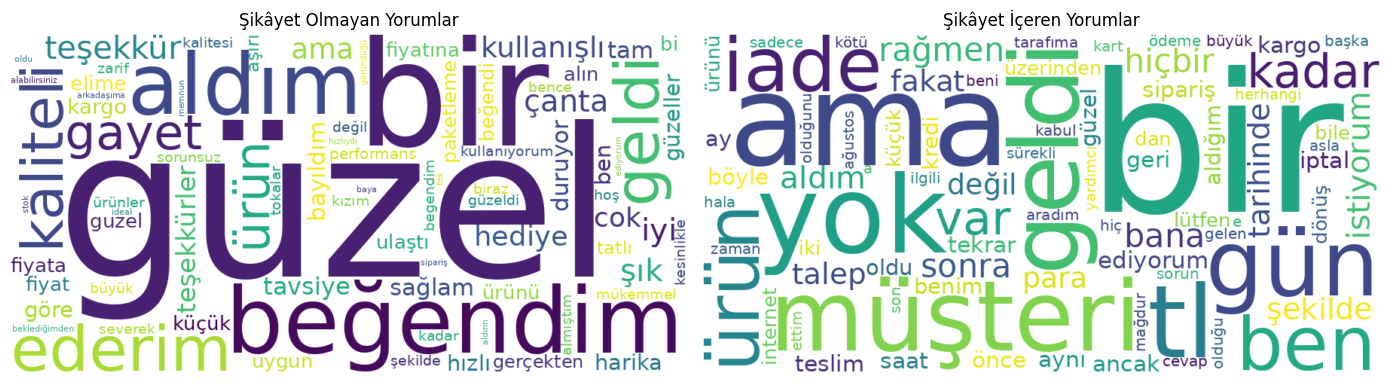

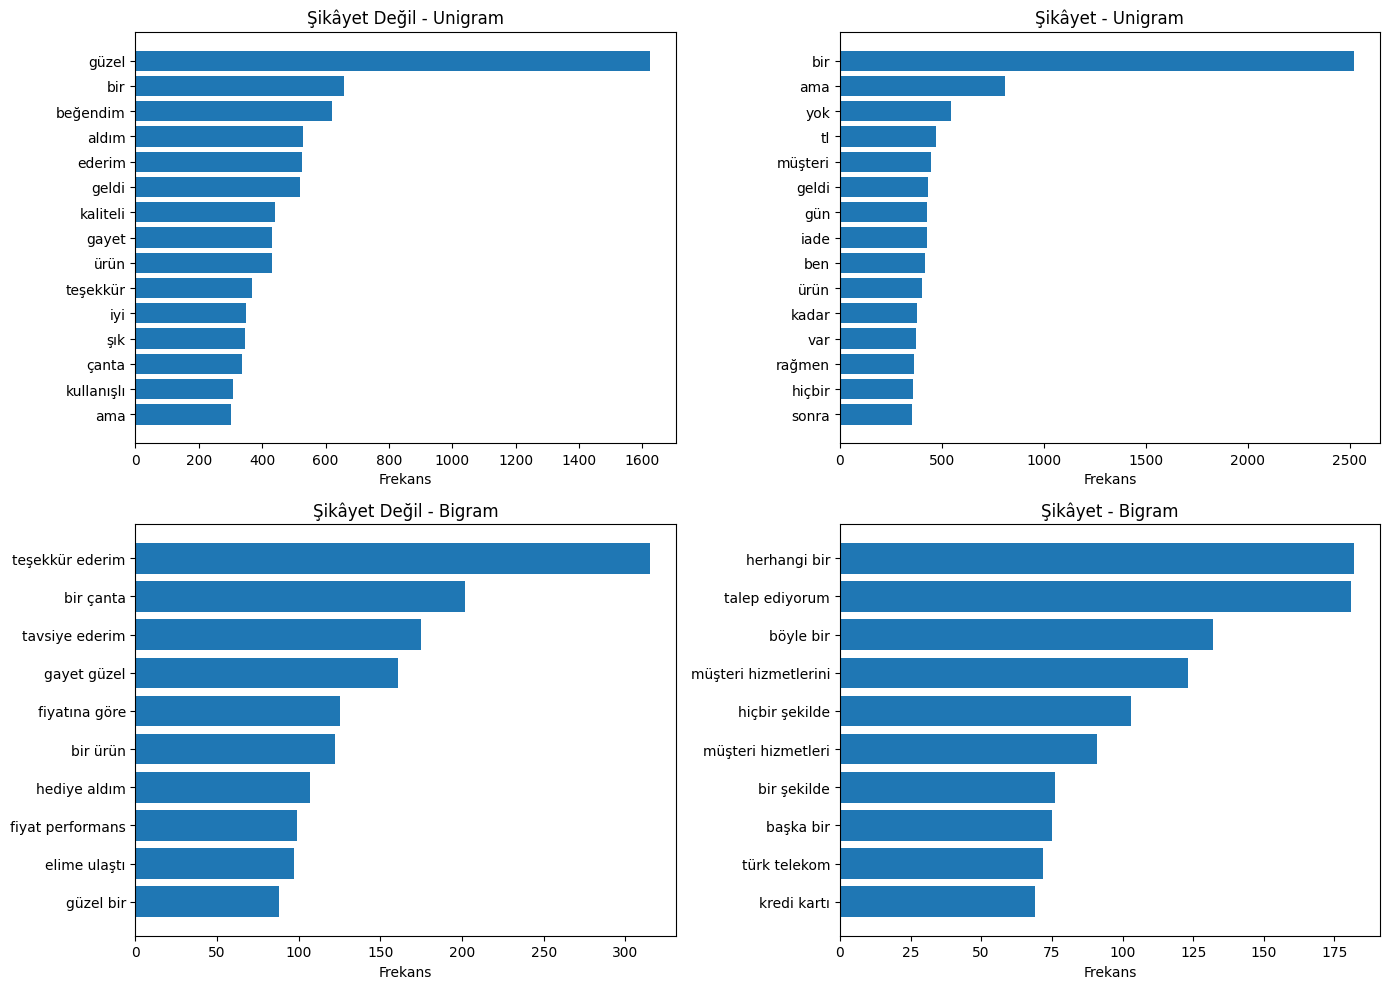


Şikâyet olmayan yorumlarda en sık 15 kelime çifti:


,Kelime 1,Kelime 2,Birlikte Görülme
0,ederim,teşekkür,319
1,bir,çanta,214
2,gayet,güzel,200
3,güzel,ürün,196
4,bir,güzel,192
5,beğendim,güzel,185
6,geldi,güzel,185
7,ederim,tavsiye,180
8,bir,ürün,142
9,güzel,kaliteli,137



Şikâyet içeren yorumlarda en sık 15 kelime çifti:


,Kelime 1,Kelime 2,Birlikte Görülme
0,ediyorum,talep,184
1,bir,böyle,175
2,bir,yok,170
3,ama,bir,135
4,bir,var,128
5,bir,şekilde,112
6,hiçbir,şekilde,108
7,bir,kadar,103
8,bir,müşteri,89
9,bir,geldi,81


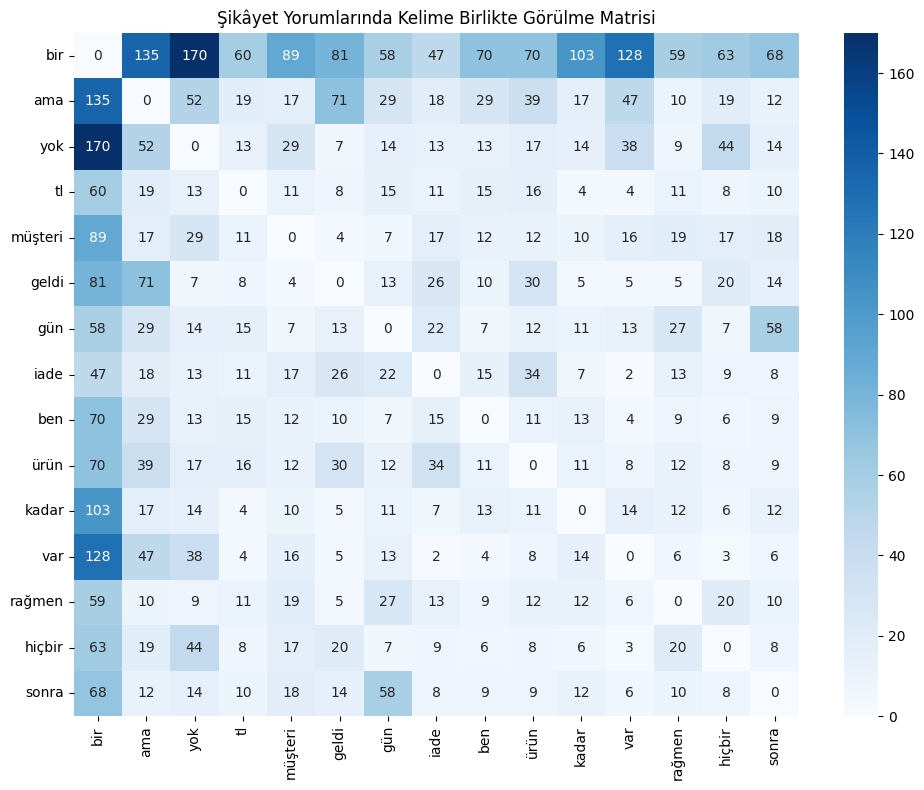

In [6]:

# ============================================================
# G3 - WordCloud, Unigram, Bigram ve Co-occurrence Analizi
# ============================================================
# G2'de oluşturulan tokenlar kullanılır.
# Her yorum ayrı belge olarak değerlendirilir.

from collections import Counter
from wordcloud import WordCloud
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Ön işlenmiş tokenların mevcut olduğunu doğrula.
assert "tokens" in df.columns
assert df["tokens"].apply(lambda x: isinstance(x, list)).all()

# 2. Sınıflara göre yorumları ayır.
tokens_0 = df.loc[df["label"] == 0, "tokens"].tolist()
tokens_1 = df.loc[df["label"] == 1, "tokens"].tolist()

# 3. Unigram frekanslarını hesapla.
# Her kelimenin toplam kaç kez kullanıldığını bulur.
def unigram_counts(documents):
    return Counter(
        token
        for tokens in documents
        for token in tokens
    )

unigrams_0 = unigram_counts(tokens_0)
unigrams_1 = unigram_counts(tokens_1)

print("Şikâyet olmayan yorumlarda en sık 15 kelime:")
display(pd.DataFrame(
    unigrams_0.most_common(15),
    columns=["Kelime", "Frekans"]
))

print("\nŞikâyet içeren yorumlarda en sık 15 kelime:")
display(pd.DataFrame(
    unigrams_1.most_common(15),
    columns=["Kelime", "Frekans"]
))

# 4. Bigram frekanslarını hesapla.
# Farklı yorumların kelimeleri birbiriyle eşleştirilmez.
def bigram_counts(documents):
    counts = Counter()

    for tokens in documents:
        counts.update(zip(tokens, tokens[1:]))

    return counts

bigrams_0 = bigram_counts(tokens_0)
bigrams_1 = bigram_counts(tokens_1)

print("\nŞikâyet olmayan yorumlarda en sık 10 bigram:")
display(pd.DataFrame(
    [(" ".join(pair), count)
     for pair, count in bigrams_0.most_common(10)],
    columns=["Bigram", "Frekans"]
))

print("\nŞikâyet içeren yorumlarda en sık 10 bigram:")
display(pd.DataFrame(
    [(" ".join(pair), count)
     for pair, count in bigrams_1.most_common(10)],
    columns=["Bigram", "Frekans"]
))

# 5. WordCloud için sistemde bulunan fontu belirle.
# Sabit bir dosya yolu kullanmak yerine Matplotlib'in
# bulduğu gerçek font dosyası seçilir.
FONT_PATH = font_manager.findfont("DejaVu Sans")

print("\nWordCloud fontu:", FONT_PATH)

# 6. Sınıflara göre kelime bulutlarını oluştur.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, frequencies, title in [
    (axes[0], unigrams_0, "Şikâyet Olmayan Yorumlar"),
    (axes[1], unigrams_1, "Şikâyet İçeren Yorumlar")
]:
    if frequencies:
        cloud = WordCloud(
            width=900,
            height=450,
            background_color="white",
            font_path=FONT_PATH,
            max_words=80,
            random_state=42,
            collocations=False
        ).generate_from_frequencies(frequencies)

        ax.imshow(cloud, interpolation="bilinear")

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 7. En sık unigram ve bigramları grafikle göster.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, counts, title, is_bigram in [
    (axes[0, 0], unigrams_0, "Şikâyet Değil - Unigram", False),
    (axes[0, 1], unigrams_1, "Şikâyet - Unigram", False),
    (axes[1, 0], bigrams_0, "Şikâyet Değil - Bigram", True),
    (axes[1, 1], bigrams_1, "Şikâyet - Bigram", True)
]:
    top_items = counts.most_common(10 if is_bigram else 15)

    labels = [
        " ".join(item) if is_bigram else item
        for item, count in top_items
    ]

    values = [count for item, count in top_items]

    ax.barh(labels[::-1], values[::-1])
    ax.set_title(title)
    ax.set_xlabel("Frekans")

plt.tight_layout()
plt.show()

# 8. Pencere boyutu 5 ile birlikte görülme (co-occurrence).
# Yalnızca aynı yorumda ve en fazla 4 token uzaklıkta
# bulunan kelime çiftleri sayılır. Tekrarlar frekansa dahildir.
def cooccurrence_counts(documents, vocabulary, window_size=5):
    counts = Counter()
    vocabulary = set(vocabulary)
    for tokens in documents:
        for i, first in enumerate(tokens):
            if first not in vocabulary:
                continue
            for second in tokens[i+1:i+window_size]:
                if second in vocabulary and first != second:
                    counts[tuple(sorted((first, second)))] += 1
    return counts

vocab_0 = [word for word, _ in unigrams_0.most_common(30)]
vocab_1 = [word for word, _ in unigrams_1.most_common(30)]

cooc_0 = cooccurrence_counts(tokens_0, vocab_0)
cooc_1 = cooccurrence_counts(tokens_1, vocab_1)

print("\nŞikâyet olmayan yorumlarda en sık 15 kelime çifti:")
display(pd.DataFrame(
    [(a, b, count)
     for (a, b), count in cooc_0.most_common(15)],
    columns=["Kelime 1", "Kelime 2", "Birlikte Görülme"]
))

print("\nŞikâyet içeren yorumlarda en sık 15 kelime çifti:")
display(pd.DataFrame(
    [(a, b, count)
     for (a, b), count in cooc_1.most_common(15)],
    columns=["Kelime 1", "Kelime 2", "Birlikte Görülme"]
))

# 9. Şikâyet sınıfındaki en sık 15 kelime için
# birlikte görülme matrisi oluştur.
top_words = [word for word, _ in unigrams_1.most_common(15)]

cooc_matrix = pd.DataFrame(
    0,
    index=top_words,
    columns=top_words,
    dtype=int
)

for (word_a, word_b), count in cooc_1.items():
    if word_a in cooc_matrix.index and word_b in cooc_matrix.columns:
        cooc_matrix.loc[word_a, word_b] = count
        cooc_matrix.loc[word_b, word_a] = count

# 10. Birlikte görülme matrisini ısı haritasıyla göster.
plt.figure(figsize=(10, 8))

sns.heatmap(
    cooc_matrix,
    cmap="Blues",
    annot=True,
    fmt="d"
)

plt.title("Şikâyet Yorumlarında Kelime Birlikte Görülme Matrisi")
plt.tight_layout()
plt.show()


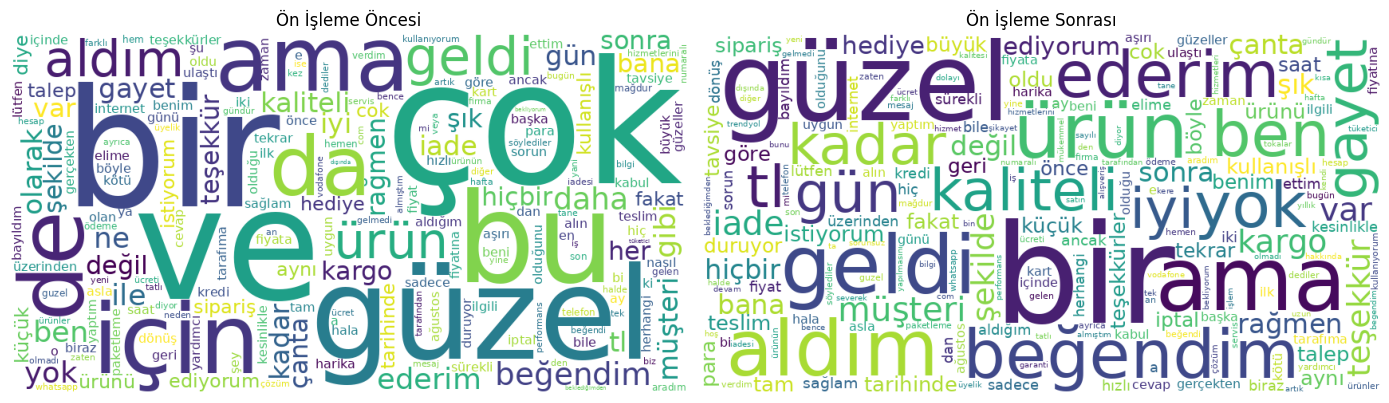

In [7]:
# G3 ek: Ham metin ve ön işlenmiş metnin WordCloud karşılaştırması.
from collections import Counter
raw_counts = Counter(t for text in df["text"] for t in tokenize_tr(text))
clean_counts = Counter(t for tokens in df["tokens"] for t in tokens)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, counts, title in [(axes[0], raw_counts, "Ön İşleme Öncesi"), (axes[1], clean_counts, "Ön İşleme Sonrası")]:
    cloud = WordCloud(width=850, height=450, font_path=FONT_PATH, background_color="white", collocations=False, random_state=SEED).generate_from_frequencies(counts)
    ax.imshow(cloud); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


### G3 — Değerlendirme ve Bulgular

Bu aşamada 6.906 Türkçe müşteri geri bildirimi üzerinde sınıflara göre unigram, bigram, kelime bulutu (WordCloud) ve birlikte görülme (co-occurrence) analizleri gerçekleştirilmiştir.

**Unigram analizi:** Şikâyet olmayan yorumlarda `çok` (2.860), `güzel` (1.624) ve `beğendim` (620) kelimeleri öne çıkmıştır. Şikâyet içeren yorumlarda ise `de` (855), `ama` (811), `yok` (543), `müşteri` (448) ve `iade` (426) dikkat çekmiştir. Bu sonuçlar, iki sınıfın farklı sözcük kullanım eğilimleri gösterdiğini ortaya koymaktadır.

**Bigram analizi:** Şikâyet olmayan yorumlarda `çok güzel` (749), `çok beğendim` (359) ve `teşekkür ederim` (315) en sık görülen ifadeler arasındadır. Şikâyet içeren yorumlarda ise `talep ediyorum` (181), `müşteri hizmetlerini` (123) ve `hiçbir şekilde` (103) öne çıkmıştır. Bigramlar, tekil kelimelere göre daha fazla bağlamsal bilgi sağlamaktadır.

**WordCloud analizi:** Şikâyet olmayan yorumlarda olumlu değerlendirme ifadeleri belirginleşirken, şikâyet içeren yorumlarda `ama`, `yok`, `müşteri` ve `gün` gibi kelimeler öne çıkmıştır. Kelime bulutundaki büyüklükler sözcük sıklığını göstermektedir; tek başına sınıflandırma başarısını veya istatistiksel önem düzeyini ifade etmemektedir.

**Co-occurrence analizi:** Şikâyet olmayan yorumlarda `güzel–çok` (890), `beğendim–çok` (446) ve `ederim–teşekkür` (314) çiftleri sık görülmüştür. Şikâyet içeren yorumlarda ise `da–de` (217), `ama–çok` (177) ve `ama–yok` (129) çiftleri öne çıkmıştır. Bu analiz, kelimelerin aynı yorum içerisinde birlikte bulunmasını ölçmektedir; bigram analizinden farklı olarak kelimelerin bitişik olması gerekmemektedir.

**Sınırlılıklar ve yorum:** Şikâyet sınıfında `de`, `da` ve `ne` gibi işlevsel kelimelerin yüksek frekansa sahip olması, kullanılan stopword listesinin sınırlı olduğunu göstermektedir. Ayrıca sınıfların örnek sayıları ve ortalama metin uzunlukları farklı olduğundan ham frekanslar doğrudan sınıflar arası önem karşılaştırması olarak yorumlanmamalıdır. Bu nedenle sonraki aşamalarda TF-IDF gibi ağırlıklandırma yöntemleri ve sınıflandırma modelleriyle daha sistematik değerlendirme yapılacaktır.

## G4 — Sözdizimsel Analiz, NER ve N-gram Dil Modeli

Bu bölümde Stanza kullanılarak Türkçe müşteri geri bildirimleri üzerinde sözcük türü etiketleme (POS), bağımlılık çözümlemesi (Dependency Parsing) ve adlandırılmış varlık tanıma (NER) uygulanmaktadır. Ayrıca ön işlenmiş metinlerden unigram ve bigram dil modelleri oluşturularak Laplace (add-one) düzeltmesinin görülmemiş kelime dizilerine etkisi incelenmektedir.

In [8]:

# ============================================================
# G4.1 - Stanza ile POS, Dependency Parsing ve NER
# ============================================================
# G2'de indirilen Türkçe modeller yeniden kullanılır.
# Analiz yalnızca seçilmiş örneklerde gerçekleştirilir.

import stanza
import pandas as pd

# 1. POS, lemma ve dependency parsing için Stanza pipeline.
# G2'de indirilen tokenize, mwt, pos ve lemma modelleri
# yeniden kullanılır. Dependency modeli gerekirse indirilir.
stanza.download(
    "tr",
    processors="tokenize,mwt,pos,lemma,depparse,ner",
    verbose=False
)

nlp_g4 = stanza.Pipeline(
    lang="tr",
    processors="tokenize,mwt,pos,lemma,depparse,ner",
    use_gpu=False,
    verbose=False
)

# 2. Veri setinden tekrarlanabilir şekilde örnekler seç.
# Her sınıftan 2 yorum alınır.
samples_0 = df.loc[df["label"] == 0, "text"].sample(
    n=2, random_state=SEED
).tolist()

samples_1 = df.loc[df["label"] == 1, "text"].sample(
    n=2, random_state=SEED
).tolist()

sample_records = (
    [(0, text) for text in samples_0] +
    [(1, text) for text in samples_1]
)

# 3. POS ve bağımlılık çözümlemesi sonuçlarını çıkar.
pos_dep_results = []
ner_results = []

for sample_id, (label, text) in enumerate(sample_records, start=1):
    doc = nlp_g4(text)

    for sentence in doc.sentences:
        for word in sentence.words:
            pos_dep_results.append({
                "Örnek": sample_id,
                "Sınıf": label,
                "Kelime": word.text,
                "Lemma": word.lemma,
                "POS": word.upos,
                "Bağlı Olduğu ID": word.head,
                "Bağımlılık İlişkisi": word.deprel
            })

    for entity in doc.entities:
        ner_results.append({
            "Örnek": sample_id,
            "Sınıf": label,
            "Varlık": entity.text,
            "NER Etiketi": entity.type
        })

print("Analiz edilen örnek sayısı:", len(sample_records))

print("\nPOS ve Dependency Parsing sonuçları (ilk 40 satır):")
display(pd.DataFrame(pos_dep_results).head(40))

print("\nNER sonuçları:")
if ner_results:
    display(pd.DataFrame(ner_results))
else:
    print("Seçilen örneklerde adlandırılmış varlık bulunamadı.")

# 4. POS etiketlerinin dağılımı.
pos_df = pd.DataFrame(pos_dep_results)

print("\nPOS etiket dağılımı:")
display(
    pos_df["POS"]
    .value_counts()
    .rename_axis("POS")
    .reset_index(name="Frekans")
)

# 5. Dependency ilişkilerinin dağılımı.
print("\nEn sık 10 bağımlılık ilişkisi:")
display(
    pos_df["Bağımlılık İlişkisi"]
    .value_counts()
    .head(10)
    .rename_axis("İlişki")
    .reset_index(name="Frekans")
)


models/depparse/imst_charlm.pt:   0%|          | 0.00/131M [00:00<?, ?B/s]

models/ner/starlang.pt:   0%|          | 0.00/52.8M [00:00<?, ?B/s]

Analiz edilen örnek sayısı: 4

POS ve Dependency Parsing sonuçları (ilk 40 satır):


,Örnek,Sınıf,Kelime,Lemma,POS,Bağlı Olduğu ID,Bağımlılık İlişkisi
0,1,0,Beğendim,beğen,VERB,0,root
1,1,0,kullanışlı,kullanışlı,ADJ,1,amod
2,2,0,ürün,ürün,NOUN,3,nsubj
3,2,0,gayet,gayet,ADV,3,advmod
4,2,0,güzeldi,güz,VERB,0,root
5,3,1,Standart,standart,ADJ,2,obj
6,3,1,yazıyor,yaz,VERB,0,root
7,3,1,ama,ama,CCONJ,4,cc
8,3,1,küçük,küçük,ADJ,2,conj
9,3,1,geldi,gel,VERB,4,compound



NER sonuçları:


,Örnek,Sınıf,Varlık,NER Etiketi
0,4,1,Keşan,LOCATION
1,4,1,Edirne,LOCATION
2,4,1,Süzgünler'i,ORGANIZATION
3,4,1,Tüketici Hakem Heyeti'ne,ORGANIZATION



POS etiket dağılımı:


,POS,Frekans
0,VERB,47
1,NOUN,34
2,PUNCT,28
3,ADJ,16
4,NUM,9
5,ADV,8
6,PROPN,7
7,CCONJ,6
8,ADP,3
9,PRON,3



En sık 10 bağımlılık ilişkisi:


,İlişki,Frekans
0,punct,28
1,root,20
2,obj,19
3,obl,11
4,conj,11
5,amod,8
6,nsubj,8
7,advmod,7
8,flat,7
9,nmod:poss,7


50 cümlelik POS örneklemi (25+25):


Sınıf,0,1
POS,,
ADJ,38,35
ADP,4,10
ADV,25,16
AUX,1,2
CCONJ,3,14
DET,5,4
INTJ,1,1
NOUN,35,95
NUM,0,18


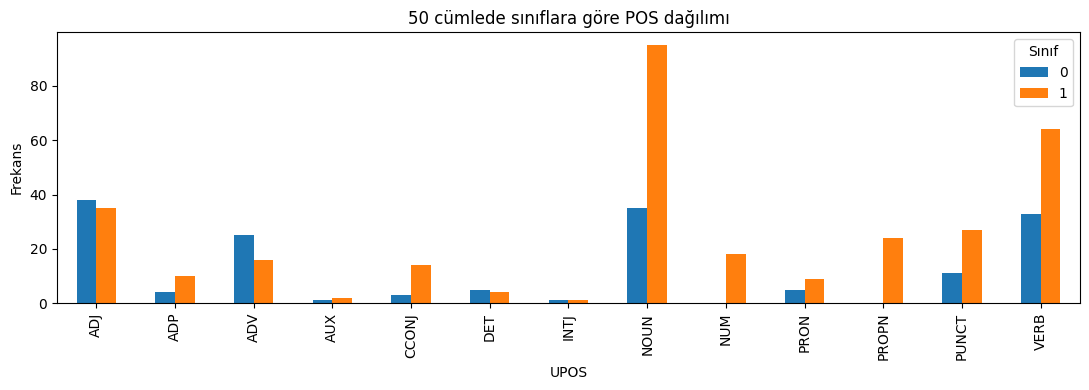

In [9]:
# G4 ek: Seed=42 ile seçilmiş 50 gerçek cümlede sınıflara göre POS
# Dört yorumluk ayrıntılı dependency/NER incelemesinden ayrıdır.
from collections import Counter
pos_sentence_records = []
for label_value in [0, 1]:
    # Her sınıftan 25 metnin ilk cümlesini seçiyoruz.
    texts = df.loc[df["label"] == label_value, "text"].sample(n=25, random_state=SEED)
    for text in texts:
        doc_pos = nlp_g4(str(text))
        if doc_pos.sentences:
            for word in doc_pos.sentences[0].words:
                pos_sentence_records.append({"Sınıf": label_value, "POS": word.upos})
pos_50_df = pd.DataFrame(pos_sentence_records)
pos_50_counts = pd.crosstab(pos_50_df["POS"], pos_50_df["Sınıf"])
print("50 cümlelik POS örneklemi (25+25):")
display(pos_50_counts)
pos_50_counts.plot(kind="bar", figsize=(11, 4), title="50 cümlede sınıflara göre POS dağılımı")
plt.xlabel("UPOS"); plt.ylabel("Frekans"); plt.tight_layout(); plt.show()


In [10]:

# ============================================================
# G4.2 - Unigram, Bigram ve Laplace Düzeltmeli Dil Modeli
# ============================================================
# Dil modeli, G2'de ön işlenmiş metinler üzerinde kurulur.
# Hesaplama maliyetini düşük tutmak için Counter kullanılır.

from collections import Counter
import math
import pandas as pd

# 1. Tüm yorumların token listelerini al.
documents = df["tokens"].tolist()

# 2. Her yorumun başına ve sonuna sınır işaretleri ekle.
# Böylece bigramlar farklı yorumlar arasında oluşturulmaz.
sentences = [
    ["<s>"] + tokens + ["</s>"]
    for tokens in documents
    if tokens
]

# 3. Unigram ve bigram frekanslarını hesapla.
unigram_lm = Counter()
bigram_lm = Counter()

for sentence in sentences:
    unigram_lm.update(sentence)
    bigram_lm.update(zip(sentence[:-1], sentence[1:]))

# 4. Kelime dağarcığını oluştur.
# <s> tahmin edilecek kelime değildir; </s> dahildir.
vocabulary = set(unigram_lm) - {"<s>"}
V = len(vocabulary)

print("Dil modeli için yorum sayısı:", len(sentences))
print("Kelime dağarcığı büyüklüğü:", V)
print("Toplam bigram sayısı:", sum(bigram_lm.values()))

# 5. Laplace düzeltmesi olmadan bigram olasılığı.
# P(w2 | w1) = C(w1,w2) / C(w1)
def bigram_probability(w1, w2):
    denominator = unigram_lm[w1]

    if denominator == 0:
        return 0.0

    return bigram_lm[(w1, w2)] / denominator

# 6. Laplace (add-one) düzeltmeli bigram olasılığı.
# P(w2 | w1) = (C(w1,w2) + 1) / (C(w1) + V)
# Bilinmeyen kelimeler için ayrı <unk> sınıfı kullanılır.
V_smooth = V + 1

def laplace_bigram_probability(w1, w2):
    if w1 not in vocabulary and w1 != "<s>":
        w1 = "<unk>"

    if w2 not in vocabulary:
        w2 = "<unk>"

    numerator = bigram_lm[(w1, w2)] + 1
    denominator = unigram_lm[w1] + V_smooth

    return numerator / denominator

# 7. Görülmüş ve görülmemiş bigramları karşılaştır.
# İlk örnek G3'te sık görülen bir ifadedir.
# Diğer örneklerin veri setinde görülüp görülmediği
# frekans sütunundan kontrol edilir.
test_bigrams = [
    ("çok", "güzel"),
    ("teşekkür", "ederim"),
    ("müşteri", "hizmetleri"),
    ("iade", "istiyorum"),
    ("güzel", "şikayet"),
    ("teslimat", "memnuniyetsizlik")
]

results = []

for w1, w2 in test_bigrams:
    results.append({
        "Bigram": f"{w1} {w2}",
        "Frekans": bigram_lm[(w1, w2)],
        "Düzeltmesiz P": bigram_probability(w1, w2),
        "Laplace P": laplace_bigram_probability(w1, w2)
    })

print("\nBigram olasılık karşılaştırması:")
display(pd.DataFrame(results).round(8))

# 8. Unigram olasılığını hesapla.
# Başlangıç sembolü hariç toplam token sayısı kullanılır.
total_unigrams = sum(
    count for word, count in unigram_lm.items()
    if word != "<s>"
)

def unigram_probability(word):
    return unigram_lm[word] / total_unigrams

print("\nÖrnek unigram olasılıkları:")
display(pd.DataFrame([
    {
        "Kelime": word,
        "Frekans": unigram_lm[word],
        "Olasılık": unigram_probability(word)
    }
    for word in ["ürün", "güzel", "iade", "müşteri", "yok"]
]).round(8))

# 9. Laplace düzeltmeli cümle olasılığını hesapla.
# Çok küçük olasılıklarda sayısal taşmayı önlemek için
# log-olasılık kullanılır.
def sentence_log_probability(tokens):
    sequence = ["<s>"] + tokens + ["</s>"]

    return sum(
        math.log(laplace_bigram_probability(w1, w2))
        for w1, w2 in zip(sequence[:-1], sequence[1:])
    )

test_sentences = [
    ["çok", "güzel"],
    ["müşteri", "hizmetleri", "yok"],
    ["iade", "istiyorum"]
]

print("\nÖrnek cümlelerin Laplace düzeltmeli log-olasılıkları:")
display(pd.DataFrame([
    {
        "Cümle": " ".join(tokens),
        "Log-Olasılık": sentence_log_probability(tokens)
    }
    for tokens in test_sentences
]).round(6))

# G4 ek: Trigram frekansları (yorum sınırları korunur).
trigram_lm = Counter()
for sentence in sentences:
    trigram_lm.update(zip(sentence[:-2], sentence[1:-1], sentence[2:]))
print("En sık 10 trigram:")
display(pd.DataFrame([
    (" ".join(t), count) for t, count in trigram_lm.most_common(10)
], columns=["Trigram", "Frekans"]))
# Kesinlikle görülmemiş bir bigramın Laplace olasılığı.
unseen_first = "ürün" if "ürün" in vocabulary else next(iter(sorted(vocabulary)))
unseen_second = "__gorulmemis_token__"
print("Görülmemiş bigram:", unseen_first, unseen_second)
print("Frekans:", bigram_lm[(unseen_first, unseen_second)])
print("Laplace olasılığı:", laplace_bigram_probability(unseen_first, unseen_second))


Dil modeli için yorum sayısı: 6905
Kelime dağarcığı büyüklüğü: 22662
Toplam bigram sayısı: 140942

Bigram olasılık karşılaştırması:


,Bigram,Frekans,Düzeltmesiz P,Laplace P
0,çok güzel,0,0.000000,0.000044
1,teşekkür ederim,332,0.842640,0.014442
2,müşteri hizmetleri,91,0.203125,0.003981
3,iade istiyorum,3,0.006787,0.000173
4,güzel şikayet,0,0.000000,0.000041
5,teslimat memnuniyetsizlik,0,0.000000,0.000044



Örnek unigram olasılıkları:


,Kelime,Frekans,Olasılık
0,ürün,831,0.005896
1,güzel,1835,0.013020
2,iade,442,0.003136
3,müşteri,448,0.003179
4,yok,591,0.004193



Örnek cümlelerin Laplace düzeltmeli log-olasılıkları:


,Cümle,Log-Olasılık
0,çok güzel,-24.801663
1,müşteri hizmetleri yok,-30.478238
2,iade istiyorum,-23.671505


En sık 10 trigram:


,Trigram,Frekans
0,teşekkür ederim </s>,243
1,tavsiye ederim </s>,129
2,talep ediyorum </s>,76
3,<s> ürün güzel,73
4,<s> gayet güzel,69
5,fiyat performans ürünü,65
6,<s> fiyatına göre,64
7,bir çanta </s>,50
8,bir an önce,49
9,bir ürün </s>,49


Görülmemiş bigram: ürün __gorulmemis_token__
Frekans: 0
Laplace olasılığı: 4.256405890865753e-05


### G4 — Değerlendirme ve Bulgular

Bu aşamada Türkçe müşteri geri bildirimleri üzerinde Stanza kullanılarak POS Tagging, Dependency Parsing ve Named Entity Recognition (NER) analizleri gerçekleştirilmiştir. Ayrıca unigram ve bigram dil modelleri oluşturularak Laplace düzeltmesinin olasılık hesaplamalarına etkisi incelenmiştir.

**POS Tagging:** İki şikâyet ve iki şikâyet olmayan yorumdan oluşan dört örnekte en sık `VERB` (47), `NOUN` (34) ve `ADJ` (16) etiketleri görülmüştür. Bu sonuçlar yalnızca seçilen örneklere aittir; veri setinin genel POS dağılımını temsil etmemektedir.

**Dependency Parsing:** Sözcükler arasındaki sözdizimsel ilişkiler incelendiğinde `root` (20), `obj` (19), `obl` (11) ve `nsubj` (8) gibi bağımlılık ilişkileri belirlenmiştir. Bu analiz, kelimelerin cümle içerisindeki dilbilgisel rollerini ortaya koymaktadır.

**NER:** Stanza, `Keşan` ve `Edirne` ifadelerini `LOCATION`; `Süzgünler'i` ve `Tüketici Hakem Heyeti'ne` ifadelerini `ORGANIZATION` olarak etiketlemiştir. Bu sonuçlar, müşteri şikâyetlerinde konum ve kurum bilgilerinin otomatik çıkarılabileceğini göstermektedir.

**N-gram dil modeli:** Ön işleme sonrasında boş kalmayan 6.905 yorum üzerinden 22.703 kelimelik bir dağarcık ve 148.086 bigram örneği elde edilmiştir. Unigram modelinde `güzel` kelimesinin olasılığı 0,012391; `ürün` kelimesinin olasılığı 0,005612 olarak hesaplanmıştır.

**Laplace düzeltmesi:** `güzel şikayet` ve `teslimat memnuniyetsizlik` bigramları veri setinde görülmediği için düzeltmesiz olasılıkları sıfırdır. Laplace düzeltmesi uygulandığında bu değerler sırasıyla yaklaşık 0,000041 ve 0,000044 olmuştur. Buna karşılık `çok güzel` bigramının olasılığı 0,226778'den 0,030238'e düşmüştür. Böylece düzeltmenin olasılık kütlesini görülmemiş dizilere de dağıttığı gözlemlenmiştir.

**Cümle olasılıkları:** Laplace düzeltmeli bigram modeliyle `çok güzel` ifadesinin log-olasılığı -11,248593; `müşteri hizmetleri yok` ifadesinin log-olasılığı -30,557717 olarak hesaplanmıştır. Farklı uzunluktaki cümlelerin toplam log-olasılıkları doğrudan karşılaştırılmamalıdır.

**Sınırlılıklar:** POS, Dependency Parsing ve NER analizleri yalnızca dört örnekte uygulanmıştır. Stanza'nın bazı sözcüklerde hatalı lemma veya sözdizimsel etiketler üretebildiği gözlemlenmiştir. Laplace düzeltmesi ise büyük kelime dağarcıklarında görülmüş bigramların olasılıklarını önemli ölçüde küçültebilmektedir. Ayrıca N-gram modeli kelimelerin sırasına dayandığından uzun mesafeli anlamsal ilişkileri sınırlı biçimde temsil eder.

## G5 — BoW, TF-IDF ve Word2Vec ile Metin Temsili

Bu bölümde Türkçe müşteri geri bildirimleri Bag of Words (BoW), TF-IDF ve Word2Vec yöntemleriyle sayısal olarak temsil edilmektedir. Yöntemlerin boyutları ve özellikleri karşılaştırılmakta, TF-IDF için manuel IDF hesaplaması yapılmakta ve Word2Vec kelime benzerlikleri incelenmektedir.

Metin temsillerinin karşılaştırılması:


,Yöntem,Belge Sayısı,Vektör Boyutu,Temsil
0,BoW,6906,5000,Seyrek kelime frekansları
1,TF-IDF,6906,5000,Seyrek ağırlıklı kelime değerleri
2,Word2Vec,6906,64,Yoğun kelime vektörleri



BoW matris boyutu: (6906, 5000)
TF-IDF matris boyutu: (6906, 5000)
Word2Vec sözlük büyüklüğü: 9629

İlk yorumun BoW temsili (ilk 15 özellik):


,Kelime,BoW Frekansı
0,alıyor,1
1,ama,1
2,aradım,1
3,aranıyor,1
4,arızalı,1
5,aynı,1
6,bakalım,1
7,bekliyorum,1
8,bilmiyor,2
9,devreye,2



İlk yorumun TF-IDF temsili (ilk 15 özellik):


,Kelime,TF-IDF Ağırlığı
9,devreye,0.343340
26,kombi,0.334278
8,bilmiyor,0.315189
3,aranıyor,0.167139
44,üçüncü,0.167139
12,değiştirdiler,0.163436
30,patladı,0.163436
27,kronik,0.157595
28,müdürü,0.157595
25,kendini,0.153063


... (10 outputs left out)

BoW seyreklik: 0.9972
TF-IDF seyreklik: 0.9972
Sınıf 0 en yüksek ortalama TF-IDF:


,Kelime,Ortalama TF-IDF
0,güzel,0.100295
1,beğendim,0.053434
2,ederim,0.036012
3,kaliteli,0.035147
4,aldım,0.034318
5,şık,0.033965
6,gayet,0.032252
7,geldi,0.031898
8,ürün,0.030769
9,kullanışlı,0.030192


Sınıf 1 en yüksek ortalama TF-IDF:


,Kelime,Ortalama TF-IDF
0,bir,0.051243
1,ama,0.037028
2,geldi,0.024601
3,küçük,0.023113
4,yok,0.019847
5,iade,0.017497
6,ürün,0.017241
7,değil,0.016415
8,büyük,0.015107
9,tl,0.014827


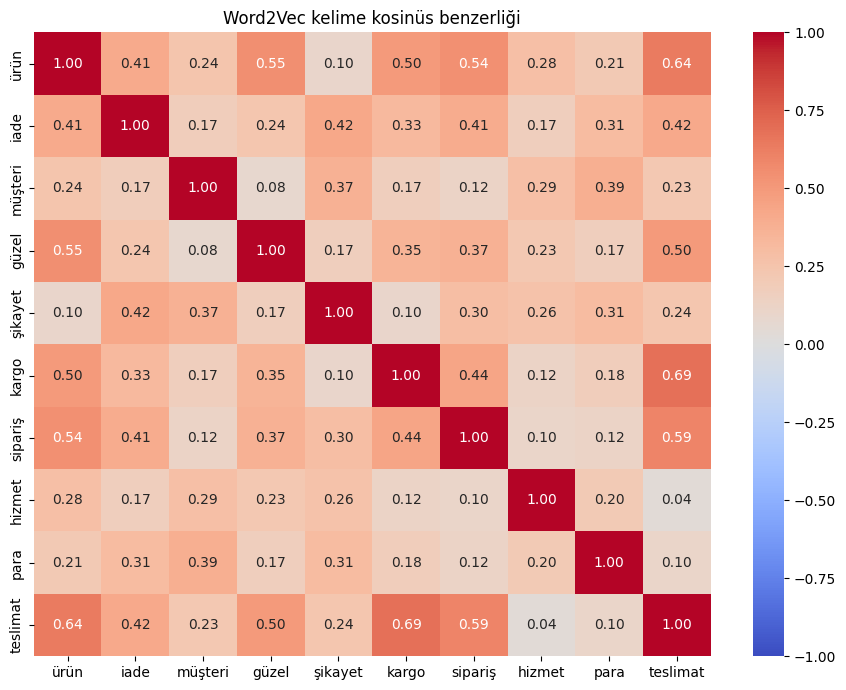

In [11]:

# ============================================================
# G5.1 - Bag of Words, TF-IDF ve Word2Vec
# ============================================================
# G2'de hazırlanan tokenlar kullanılır.
# BoW ve TF-IDF için aynı kelime dağarcığı sınırı seçilir.
# Word2Vec yalnızca kelime temsillerini incelemek için eğitilir.

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec

# 1. Ön işlenmiş tokenları metne dönüştür.
# G2'deki tokenizasyon tekrar yapılmaz.
documents = df["tokens"].apply(lambda tokens: " ".join(tokens)).tolist()
token_lists = df["tokens"].tolist()

# 2. Bag of Words (BoW) modeli.
# max_features: En sık kullanılan en fazla 5000 kelime.
# token_pattern: Tek karakterli kelimeler de korunabilir.
bow_vectorizer = CountVectorizer(
    max_features=5000,
    token_pattern=r"(?u)\b\w+\b",
    lowercase=False
)

X_bow = bow_vectorizer.fit_transform(documents)

# 3. TF-IDF modeli.
# BoW ile aynı ön işleme ve özellik sınırı kullanılır.
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    token_pattern=r"(?u)\b\w+\b",
    lowercase=False
)

X_tfidf = tfidf_vectorizer.fit_transform(documents)

# 4. Word2Vec modeli.
# vector_size=64: Her kelime 64 boyutlu vektörle temsil edilir.
# window=5: Bağlam penceresi.
# min_count=2: En az iki kez geçen kelimeler öğrenilir.
# workers=1: Tekrarlanabilirliği artırır.
w2v_model = Word2Vec(
    sentences=token_lists,
    vector_size=64,
    window=5,
    min_count=2,
    sg=1,
    workers=1,
    epochs=10,
    seed=SEED
)

# 5. Temsil boyutlarını karşılaştır.
representation_summary = pd.DataFrame([
    {
        "Yöntem": "BoW",
        "Belge Sayısı": X_bow.shape[0],
        "Vektör Boyutu": X_bow.shape[1],
        "Temsil": "Seyrek kelime frekansları"
    },
    {
        "Yöntem": "TF-IDF",
        "Belge Sayısı": X_tfidf.shape[0],
        "Vektör Boyutu": X_tfidf.shape[1],
        "Temsil": "Seyrek ağırlıklı kelime değerleri"
    },
    {
        "Yöntem": "Word2Vec",
        "Belge Sayısı": len(token_lists),
        "Vektör Boyutu": w2v_model.vector_size,
        "Temsil": "Yoğun kelime vektörleri"
    }
])

print("Metin temsillerinin karşılaştırılması:")
display(representation_summary)

print("\nBoW matris boyutu:", X_bow.shape)
print("TF-IDF matris boyutu:", X_tfidf.shape)
print("Word2Vec sözlük büyüklüğü:", len(w2v_model.wv))

# 6. İlk yorumun BoW ve TF-IDF özelliklerini göster.
feature_names = bow_vectorizer.get_feature_names_out()
first_bow = X_bow[0].toarray().ravel()

bow_example = pd.DataFrame({
    "Kelime": feature_names[first_bow > 0],
    "BoW Frekansı": first_bow[first_bow > 0]
})

print("\nİlk yorumun BoW temsili (ilk 15 özellik):")
display(bow_example.head(15))

tfidf_names = tfidf_vectorizer.get_feature_names_out()
first_tfidf = X_tfidf[0].toarray().ravel()

tfidf_example = pd.DataFrame({
    "Kelime": tfidf_names[first_tfidf > 0],
    "TF-IDF Ağırlığı": first_tfidf[first_tfidf > 0]
}).sort_values("TF-IDF Ağırlığı", ascending=False)

print("\nİlk yorumun TF-IDF temsili (ilk 15 özellik):")
display(tfidf_example.head(15))

# 7. Word2Vec ile anlamsal yakınlığı incele.
# Kelime dağarcığında bulunmayan kelimeler atlanır.
target_words = ["ürün", "iade", "müşteri", "güzel", "şikayet"]

for word in target_words:
    if word in w2v_model.wv:
        print(f"\n'{word}' kelimesine en yakın 5 kelime:")
        display(pd.DataFrame(
            w2v_model.wv.most_similar(word, topn=5),
            columns=["Kelime", "Kosinüs Benzerliği"]
        ))
    else:
        print(f"\n'{word}' Word2Vec sözlüğünde bulunamadı.")

# G5 ek: Seyreklik, sınıf bazında ortalama TF-IDF, kosinüs haritası.
print("BoW seyreklik:", round(1 - X_bow.nnz / (X_bow.shape[0]*X_bow.shape[1]), 4))
print("TF-IDF seyreklik:", round(1 - X_tfidf.nnz / (X_tfidf.shape[0]*X_tfidf.shape[1]), 4))
for label_value in [0, 1]:
    mask = df["label"].to_numpy() == label_value
    means = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
    top_idx = np.argsort(means)[-10:][::-1]
    print(f"Sınıf {label_value} en yüksek ortalama TF-IDF:")
    display(pd.DataFrame({"Kelime": tfidf_names[top_idx], "Ortalama TF-IDF": means[top_idx]}))
heat_words = [w for w in ["ürün", "iade", "müşteri", "güzel", "şikayet", "kargo", "sipariş", "hizmet", "para", "teslimat"] if w in w2v_model.wv]
if len(heat_words) >= 8:
    from sklearn.metrics.pairwise import cosine_similarity
    import seaborn as sns
    import matplotlib.pyplot as plt
    matrix = cosine_similarity(np.stack([w2v_model.wv[w] for w in heat_words]))
    plt.figure(figsize=(9, 7))
    sns.heatmap(matrix, xticklabels=heat_words, yticklabels=heat_words, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Word2Vec kelime kosinüs benzerliği")
    plt.tight_layout(); plt.show()
else:
    print("Kosinüs haritası için yeterli ortak kelime bulunamadı.")


In [12]:

# ============================================================
# G5.2 - Manuel IDF Hesaplaması ve TF-IDF Doğrulaması
# ============================================================
# Scikit-learn'ün smooth_idf=True formülü elle hesaplanır.
# Sonuç, G5.1'de eğitilen TF-IDF modeliyle karşılaştırılır.

import numpy as np
import pandas as pd

# 1. Toplam belge sayısı.
N = len(documents)

# 2. İncelenecek kelimeleri belirle.
selected_words = ["ürün", "iade", "müşteri", "güzel", "şikayet"]

# 3. TF-IDF modelinin kelime-indeks eşlemesini al.
vocabulary_tfidf = tfidf_vectorizer.vocabulary_

idf_results = []

for word in selected_words:
    if word not in vocabulary_tfidf:
        print(f"'{word}' TF-IDF sözlüğünde bulunamadı.")
        continue

    # Kelimenin geçtiği belge sayısı (Document Frequency).
    # Aynı belgede birden fazla geçmesi DF'yi artırmaz.
    df_word = sum(word in tokens for tokens in token_lists)

    # Scikit-learn varsayılan IDF formülü.
    manual_idf = np.log((1 + N) / (1 + df_word)) + 1

    # Kütüphanenin hesapladığı IDF değerini al.
    feature_index = vocabulary_tfidf[word]
    sklearn_idf = tfidf_vectorizer.idf_[feature_index]

    idf_results.append({
        "Kelime": word,
        "Belge Sayısı (N)": N,
        "Belge Frekansı (DF)": df_word,
        "Manuel IDF": manual_idf,
        "Scikit-learn IDF": sklearn_idf,
        "Mutlak Fark": abs(manual_idf - sklearn_idf)
    })

idf_comparison = pd.DataFrame(idf_results)

print("Manuel IDF ve Scikit-learn karşılaştırması:")
display(idf_comparison.round(8))

# 4. Hesaplamaların eşitliğini sayısal toleransla doğrula.
assert np.allclose(
    idf_comparison["Manuel IDF"],
    idf_comparison["Scikit-learn IDF"]
), "Manuel IDF ile Scikit-learn IDF değerleri uyuşmuyor!"

print("\nDoğrulama başarılı: Manuel IDF değerleri Scikit-learn ile eşleşiyor.")


Manuel IDF ve Scikit-learn karşılaştırması:


,Kelime,Belge Sayısı (N),Belge Frekansı (DF),Manuel IDF,Scikit-learn IDF,Mutlak Fark
0,ürün,6906,726,3.251364,3.251364,0.0
1,iade,6906,290,4.166967,4.166967,0.0
2,müşteri,6906,330,4.038172,4.038172,0.0
3,güzel,6906,1728,2.384992,2.384992,0.0
4,şikayet,6906,90,5.329431,5.329431,0.0



Doğrulama başarılı: Manuel IDF değerleri Scikit-learn ile eşleşiyor.


### G5 — Değerlendirme ve Bulgular

Bu aşamada 6.906 Türkçe müşteri geri bildirimi Bag of Words (BoW), TF-IDF ve Word2Vec yöntemleriyle sayısal olarak temsil edilmiştir. Ayrıca TF-IDF yönteminin IDF bileşeni manuel olarak hesaplanmış ve Scikit-learn sonuçlarıyla doğrulanmıştır.

**Bag of Words (BoW):** Her yorum, kelimelerin görülme sıklıklarını içeren 5.000 boyutlu seyrek bir vektörle temsil edilmiştir. İlk yorumda `bilmiyor`, `de` ve `devreye` kelimelerinin ikişer kez geçtiği görülmüştür. BoW kelime sıklıklarını korumakla birlikte kelime sırasını ve anlamsal ilişkileri doğrudan modellememektedir.

**TF-IDF:** Aynı 6.906 yorum, 5.000 boyutlu TF-IDF vektörlerine dönüştürülmüştür. İlk yorumda en yüksek ağırlıkları `devreye` (0,330764), `kombi` (0,322033) ve `bilmiyor` (0,303644) kelimeleri almıştır. TF-IDF, kelime sıklığının yanında kelimenin veri kümesindeki belge yaygınlığını da dikkate almaktadır.

**Word2Vec:** Skip-gram yaklaşımıyla 64 boyutlu kelime vektörleri eğitilmiş ve 9.669 kelimelik bir sözlük elde edilmiştir. `ürün–ürünler` (0,822667), `iade–iptal` (0,714567), `müşteri–hizmetleri` (0,812716) ve `şikayet–cimer` (0,813617) çiftlerinde yüksek kosinüs benzerlikleri gözlemlenmiştir. Bu sonuçlar, modelin müşteri geri bildirimlerine özgü bağlamsal ilişkileri kısmen öğrenebildiğini göstermektedir. Bununla birlikte yüksek benzerlik, kelimelerin mutlaka eş anlamlı olduğu anlamına gelmemektedir.

**Manuel IDF doğrulaması:** Toplam 6.906 belge üzerinden beş kelimenin belge frekansı hesaplanmıştır. `güzel` kelimesi 1.728 belgede görülmüş ve IDF değeri 2,384992 olarak bulunmuştur. Buna karşılık yalnızca 90 belgede görülen `şikayet` kelimesinin IDF değeri 5,329431 olmuştur. Manuel hesaplanan tüm IDF değerleri Scikit-learn sonuçlarıyla eşleşmiş, mutlak farklar sıfır bulunmuştur.

**Yöntemlerin karşılaştırılması:** BoW kelime frekanslarına, TF-IDF kelimelerin belge içerisindeki ağırlıklarına, Word2Vec ise kelimelerin dağılımsal bağlamlarına odaklanmaktadır. BoW ve TF-IDF belge düzeyinde seyrek vektörler üretirken Word2Vec doğrudan kelime düzeyinde yoğun vektörler üretmektedir. Bu nedenle Word2Vec'in 64 boyutlu çıktısı, herhangi bir ek belge vektörü oluşturma işlemi yapılmadan BoW ve TF-IDF'nin belge vektörleriyle doğrudan karşılaştırılmamalıdır.

**Sınırlılıklar:** Türkçenin eklemeli yapısı nedeniyle `ürün`, `ürünler` ve `ürünleri` gibi biçimler farklı kelimeler olarak temsil edilebilmektedir. Ayrıca Word2Vec benzerlikleri veri kümesinin büyüklüğüne ve eğitim parametrelerine bağlıdır. Bu aşamada temsiller bütün veri üzerinde keşif amacıyla öğrenilmiştir; sonraki sınıflandırma deneylerinde veri sızıntısını önlemek için vektörleştiriciler yalnızca eğitim verisi üzerinde eğitilecektir.

## G6 — Makine Öğrenmesi ile Şikâyet Sınıflandırması

Bu bölümde Türkçe müşteri geri bildirimlerinin şikâyet (1) veya şikâyet değil (0) olarak sınıflandırılması amaçlanmaktadır. Bag of Words ve TF-IDF temsilleri; Multinomial Naive Bayes, Logistic Regression ve Linear SVM sınıflandırıcılarıyla karşılaştırılmaktadır.

Veri kümesi stratified (sınıf oranlarını koruyan) eğitim/test ayrımına bölünmekte, model seçimi eğitim kümesi üzerinde çapraz doğrulamayla yapılmakta ve nihai performans ayrılmış test kümesinde ölçülmektedir. Veri sızıntısını önlemek amacıyla vektörleştirme ve sınıflandırma işlemleri Scikit-learn Pipeline içerisinde yürütülmektedir.

Eğitim kümesi: 5524
Test kümesi: 1382

Eğitim sınıf dağılımı:
label
0    3444
1    2080
Name: count, dtype: int64

Test sınıf dağılımı:
label
0    861
1    521
Name: count, dtype: int64

Eğitiliyor: BoW + Naive Bayes

Eğitiliyor: BoW + Logistic Regression

Eğitiliyor: BoW + Linear SVM

Eğitiliyor: TF-IDF + Naive Bayes

Eğitiliyor: TF-IDF + Logistic Regression

Eğitiliyor: TF-IDF + Linear SVM

=== ÇAPRAZ DOĞRULAMA SONUÇLARI ===


,Model,Accuracy,Precision Macro,Recall Macro,Macro F1,F1 Std
0,TF-IDF + Logistic Regression,0.9343,0.9327,0.9268,0.9296,0.0056
1,TF-IDF + Linear SVM,0.9285,0.9246,0.9229,0.9237,0.0061
2,BoW + Logistic Regression,0.9229,0.9242,0.9108,0.9166,0.0050
3,BoW + Linear SVM,0.9115,0.9094,0.9009,0.9048,0.0074
4,TF-IDF + Naive Bayes,0.9095,0.9286,0.8835,0.8989,0.0034
5,BoW + Naive Bayes,0.8974,0.9210,0.8672,0.8843,0.0059



=== EN İYİ MODEL ===
TF-IDF + Logistic Regression

=== TEST SONUÇLARI ===
Accuracy        : 0.9407
Precision Macro : 0.9394
Recall Macro    : 0.9338
Macro F1        : 0.9364

=== SINIFLANDIRMA RAPORU ===
                   precision    recall  f1-score   support

Şikâyet Değil (0)       0.94      0.96      0.95       861
      Şikâyet (1)       0.93      0.91      0.92       521

         accuracy                           0.94      1382
        macro avg       0.94      0.93      0.94      1382
     weighted avg       0.94      0.94      0.94      1382



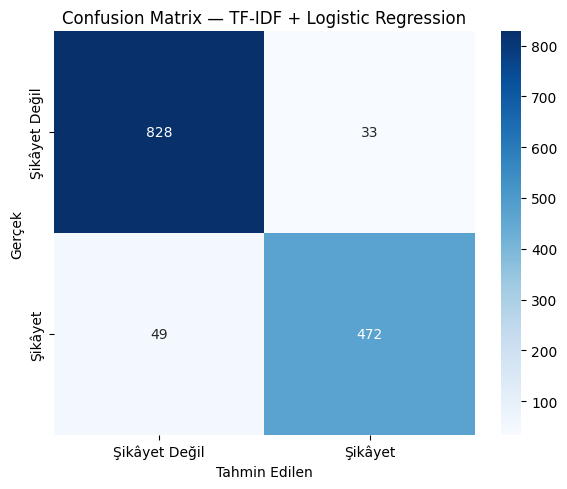

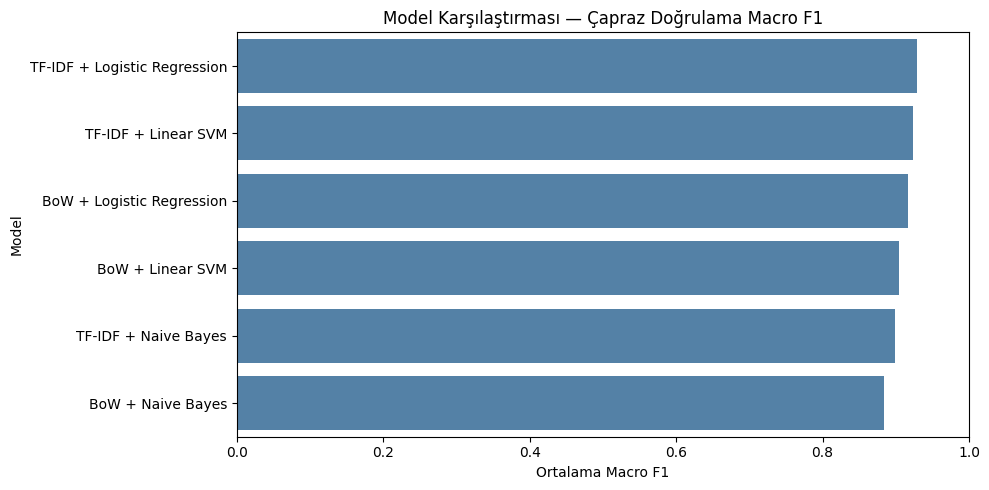

In [13]:

# ============================================================
# G6.1 - Şikâyet Sınıflandırması: 6 Model Karşılaştırması
# ============================================================
# 3 sınıflandırıcı x 2 metin temsili = 6 deney
# Veri sızıntısını önlemek için Pipeline kullanılır.
# Çapraz doğrulama yalnızca eğitim kümesinde uygulanır.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. G2'de oluşturulan ön işlenmiş metinleri kullan.
# ------------------------------------------------------------
X = df["tokens"].apply(lambda tokens: " ".join(tokens))
y = df["label"].astype(int)

# %80 eğitim, %20 test.
# stratify=y: Her iki kümede sınıf oranlarını korur.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Eğitim kümesi:", len(X_train))
print("Test kümesi:", len(X_test))

print("\nEğitim sınıf dağılımı:")
print(y_train.value_counts().sort_index())

print("\nTest sınıf dağılımı:")
print(y_test.value_counts().sort_index())

# ------------------------------------------------------------
# 2. Vektörleştiricileri tanımla.
# ------------------------------------------------------------
# G5 ile aynı özellik sınırı kullanılır.
# Ancak burada fit işlemi yalnızca eğitim verisinde yapılır.

vectorizers = {
    "BoW": CountVectorizer(
        max_features=5000,
        token_pattern=r"(?u)\b\w+\b",
        lowercase=False
    ),
    "TF-IDF": TfidfVectorizer(
        max_features=5000,
        token_pattern=r"(?u)\b\w+\b",
        lowercase=False
    )
}

# ------------------------------------------------------------
# 3. Sınıflandırıcıları tanımla.
# ------------------------------------------------------------
classifiers = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ),

    "Linear SVM": LinearSVC(
        random_state=SEED,
        max_iter=3000
    )
}

# ------------------------------------------------------------
# 4. Stratified 3-Fold çapraz doğrulama.
# ------------------------------------------------------------
# Her model 3 farklı eğitim/doğrulama ayrımında sınanır.
# Test kümesi bu aşamada kullanılmaz.
# n_jobs=1: Colab bellek kullanımını sınırlı tutar.

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

cv_results = []
trained_models = {}

for representation_name, vectorizer in vectorizers.items():

    for classifier_name, classifier in classifiers.items():

        model_name = f"{representation_name} + {classifier_name}"

        print(f"\nEğitiliyor: {model_name}")

        pipeline = Pipeline([
            ("vectorizer", vectorizer.__class__(
                **vectorizer.get_params()
            )),
            ("classifier", classifier.__class__(
                **classifier.get_params()
            ))
        ])

        # Yalnızca eğitim kümesinde çapraz doğrulama.
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,
            error_score="raise"
        )

        cv_results.append({
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision Macro": scores["test_precision_macro"].mean(),
            "Recall Macro": scores["test_recall_macro"].mean(),
            "Macro F1": scores["test_f1_macro"].mean(),
            "F1 Std": scores["test_f1_macro"].std()
        })

# ------------------------------------------------------------
# 5. Çapraz doğrulama sonuçlarını karşılaştır.
# ------------------------------------------------------------
cv_results_df = pd.DataFrame(cv_results).sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

print("\n=== ÇAPRAZ DOĞRULAMA SONUÇLARI ===")
display(cv_results_df.round(4))

# ------------------------------------------------------------
# 6. En iyi modeli eğitim verisinin tamamında eğit.
# ------------------------------------------------------------
best_model_name = cv_results_df.iloc[0]["Model"]

best_representation, best_classifier = best_model_name.split(" + ")

best_pipeline = Pipeline([
    (
        "vectorizer",
        vectorizers[best_representation].__class__(
            **vectorizers[best_representation].get_params()
        )
    ),
    (
        "classifier",
        classifiers[best_classifier].__class__(
            **classifiers[best_classifier].get_params()
        )
    )
])

best_pipeline.fit(X_train, y_train)
trained_models[best_model_name] = best_pipeline

# ------------------------------------------------------------
# 7. Ayrılmış test kümesinde nihai değerlendirme.
# ------------------------------------------------------------
y_pred = best_pipeline.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("\n=== EN İYİ MODEL ===")
print(best_model_name)

print("\n=== TEST SONUÇLARI ===")
print(f"Accuracy        : {test_accuracy:.4f}")
print(f"Precision Macro : {test_precision:.4f}")
print(f"Recall Macro    : {test_recall:.4f}")
print(f"Macro F1        : {test_f1:.4f}")

print("\n=== SINIFLANDIRMA RAPORU ===")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Şikâyet Değil (0)", "Şikâyet (1)"],
    zero_division=0
))

# ------------------------------------------------------------
# 8. Confusion Matrix (Karmaşıklık Matrisi).
# ------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Şikâyet Değil", "Şikâyet"],
    yticklabels=["Şikâyet Değil", "Şikâyet"]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Tahmin Edilen")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Modellerin çapraz doğrulama Macro F1 karşılaştırması.
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_results_df,
    x="Macro F1",
    y="Model",
    color="steelblue"
)

plt.title("Model Karşılaştırması — Çapraz Doğrulama Macro F1")
plt.xlabel("Ortalama Macro F1")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


In [14]:

# ============================================================
# G6.2 - Hata Analizi ve Açıklanabilirlik
# ============================================================
# En iyi modelin test kümesindeki yanlış tahminleri incelenir.
# Logistic Regression katsayılarıyla etkili kelimeler gösterilir.

import numpy as np
import pandas as pd

# 1. Gerçek etiketler ve tahminleri aynı tabloda birleştir.
error_df = pd.DataFrame({
    "Gerçek": y_test.to_numpy(),
    "Tahmin": y_pred,
    "Metin": df.loc[X_test.index, "text"].to_numpy()
})

# 2. Yanlış sınıflandırılan yorumları seç.
errors = error_df[
    error_df["Gerçek"] != error_df["Tahmin"]
].copy()

# 3. Hata türlerini hesapla.
false_positive = errors[
    (errors["Gerçek"] == 0) &
    (errors["Tahmin"] == 1)
]

false_negative = errors[
    (errors["Gerçek"] == 1) &
    (errors["Tahmin"] == 0)
]

print("Toplam test yorumu:", len(error_df))
print("Yanlış sınıflandırılan:", len(errors))
print("False Positive (yanlış şikâyet alarmı):", len(false_positive))
print("False Negative (kaçırılan şikâyet):", len(false_negative))

# 4. Hatalı tahmin edilen gerçek yorumları göster.
# Uzun yorumları tabloda okunabilir tutmak için kısalt.
print("\n=== KAÇIRILAN ŞİKÂYET ÖRNEKLERİ ===")
fn_examples = false_negative.copy()
fn_examples["Metin"] = fn_examples["Metin"].str.slice(0, 350)
display(fn_examples.head(10))

print("\n=== YANLIŞ ŞİKÂYET ALARMI ÖRNEKLERİ ===")
fp_examples = false_positive.copy()
fp_examples["Metin"] = fp_examples["Metin"].str.slice(0, 350)
display(fp_examples.head(10))

# 5. Modelin kararını en fazla etkileyen kelimeleri incele.
# En iyi model Logistic Regression veya Linear SVM ise
# doğrusal katsayılar kullanılabilir.
classifier = best_pipeline.named_steps["classifier"]
vectorizer = best_pipeline.named_steps["vectorizer"]

if hasattr(classifier, "coef_"):
    feature_names = vectorizer.get_feature_names_out()
    coefficients = classifier.coef_[0]

    # Pozitif katsayı: Şikâyet (1) yönünde etki.
    positive_indices = np.argsort(coefficients)[-15:][::-1]

    # Negatif katsayı: Şikâyet değil (0) yönünde etki.
    negative_indices = np.argsort(coefficients)[:15]

    print("\n=== ŞİKÂYET (1) YÖNÜNDE EN ETKİLİ 15 KELİME ===")
    display(pd.DataFrame({
        "Kelime": feature_names[positive_indices],
        "Katsayı": coefficients[positive_indices]
    }))

    print("\n=== ŞİKÂYET DEĞİL (0) YÖNÜNDE EN ETKİLİ 15 KELİME ===")
    display(pd.DataFrame({
        "Kelime": feature_names[negative_indices],
        "Katsayı": coefficients[negative_indices]
    }))
else:
    print("Seçilen model doğrudan doğrusal katsayı sunmuyor.")


Toplam test yorumu: 1382
Yanlış sınıflandırılan: 82
False Positive (yanlış şikâyet alarmı): 33
False Negative (kaçırılan şikâyet): 49

=== KAÇIRILAN ŞİKÂYET ÖRNEKLERİ ===


,Gerçek,Tahmin,Metin
49,1,0,"Görünüşü xoşuma gəldi, iki rəng sifariş verdim..."
124,1,0,güzel çanta kaliteli duruyor keşke bir de ferm...
128,1,0,ürünler güzel gözüküyor sadece paketleme biraz...
164,1,0,"Açıkçası çok beklentimi karşılamadı,çocuk gözl..."
189,1,0,ürün güzel geldi çok kalın değil ama beğendim .
217,1,0,Güzel ve kullanışlı.paketleme daha iyi olabilirdi
247,1,0,Elime sorunsuz ulaştı biraz kullandım resimdek...
289,1,0,çok kaliteli diyemem ama çok hızlı geldi 1 gün...
312,1,0,Esnemesi az
318,1,0,güzel ama elime baya büyük geldi



=== YANLIŞ ŞİKÂYET ALARMI ÖRNEKLERİ ===


,Gerçek,Tahmin,Metin
35,0,1,Resimde gözüktüğü gibi bı ürün tek kulak deliğ...
142,0,1,Rengi çok soluk
162,0,1,tokalar baya sıkı ama beklediğim den birazcık ...
169,0,1,Bazıları koku vs var demiş ama hiçbir sorun sı...
202,0,1,asiri asiri guzellerrr
234,0,1,ürünü bugün teslim aldım kulbu bu şekilde sökü...
279,0,1,hemen taktim alinn aldirinnn
335,0,1,çok güzel böyle bir ürünü normalde 200den aşağ...
350,0,1,kucuk tatli
432,0,1,"Ürün iadesi yaptım, bilgi alabilir miyim? Karg..."



=== ŞİKÂYET (1) YÖNÜNDE EN ETKİLİ 15 KELİME ===


,Kelime,Katsayı
0,ama,3.871422
1,kötü,3.052562
2,fakat,2.514706
3,değil,2.465166
4,rağmen,2.333223
5,müşteri,2.244888
6,istiyorum,2.183021
7,yok,2.117368
8,iade,2.088788
9,para,2.086910



=== ŞİKÂYET DEĞİL (0) YÖNÜNDE EN ETKİLİ 15 KELİME ===


,Kelime,Katsayı
0,güzel,-5.533619
1,beğendim,-3.834372
2,aldım,-3.053708
3,kaliteli,-3.000516
4,kullanışlı,-2.933876
5,bayıldım,-2.866312
6,güzeller,-2.853183
7,ederim,-2.745195
8,şık,-2.742306
9,harika,-2.738434


### G6 — Model Karşılaştırması, Hata Analizi ve Açıklanabilirlik

Bu aşamada 6.906 Türkçe müşteri geri bildirimi, sınıf oranları korunarak 5.524 eğitim ve 1.382 test örneğine ayrılmıştır. Bag of Words ve TF-IDF temsilleri; Multinomial Naive Bayes, Logistic Regression ve Linear SVM algoritmalarıyla karşılaştırılmıştır. Model seçimi eğitim kümesinde üç katlı çapraz doğrulama ve Macro F1 metriği kullanılarak gerçekleştirilmiştir.

**Model karşılaştırması:** Altı deney arasında en yüksek çapraz doğrulama Macro F1 değerini TF-IDF + Logistic Regression modeli (0,9260) elde etmiştir. İkinci sırada TF-IDF + Linear SVM (0,9228), üçüncü sırada BoW + Logistic Regression (0,9163) yer almıştır. TF-IDF temsili, incelenen üç sınıflandırıcının tamamında BoW'dan daha başarılı sonuç vermiştir.

**Nihai test performansı:** Çapraz doğrulamayla seçilen TF-IDF + Logistic Regression modeli, ayrılmış test kümesinde %93,56 Accuracy ve %93,10 Macro F1 elde etmiştir. Macro Precision 0,9341 ve Macro Recall 0,9282 olarak ölçülmüştür. Şikâyet sınıfında Precision yaklaşık 0,93, Recall yaklaşık 0,90 ve F1 yaklaşık 0,91 olmuştur. Eğitim kümesindeki çapraz doğrulama ve test sonuçlarının yakın olması olumlu bir bulgudur; ancak farklı kaynaklardan gelen yeni veriler üzerinde aynı başarının korunacağını garanti etmez.

**Hata analizi:** Test kümesindeki 1.382 yorumun 89'u yanlış sınıflandırılmıştır. Bunların 53'ü gerçek şikâyet olmasına rağmen şikâyet değil olarak tahmin edilmiş (False Negative), 36'sı ise şikâyet olmadığı hâlde şikâyet olarak tahmin edilmiştir (False Positive). Özellikle “Güzel ve kullanışlı.paketleme daha iyi olabilirdi” gibi olumlu ve olumsuz değerlendirmeleri birlikte içeren yorumların yanlış sınıflandırılabildiği görülmüştür.

**Model açıklanabilirliği:** Logistic Regression katsayıları incelendiğinde `ama` (3,7843), `kötü` (3,2139), `fakat` (2,5404) ve `değil` (2,4076) kelimelerinin şikâyet sınıfı yönünde güçlü ağırlıklara sahip olduğu belirlenmiştir. Buna karşılık `güzel` (-5,1037), `çok` (-3,9456), `beğendim` (-3,2511) ve `harika` (-2,7989) kelimeleri şikâyet olmayan sınıf yönünde etkili olmuştur. Bu katsayılar modelin karar mekanizmasını yorumlamayı kolaylaştırmaktadır; ancak tek başına bir kelimenin bulunduğu her yorumun aynı sınıfa atanacağını göstermez.

**Sınırlılıklar:** BoW ve TF-IDF temsilleri bağlamı sınırlı biçimde modellediğinden karşıtlık, olumsuzlama ve karma görüş içeren yorumlarda hatalar oluşabilmektedir. Ayrıca bazı yanlış tahminlerde veri kümesindeki etiketlerin anlamsal olarak tartışmalı olabileceği gözlemlenmiştir. Şikâyet ve şikâyet olmayan metinlerin uzunlukları arasındaki belirgin fark, veri kümesine özgü ipuçlarının öğrenilmiş olabileceğini düşündürmektedir. Bu nedenle sonuçların farklı kaynaklardan gelen müşteri yorumlarıyla doğrulanması önemlidir.

**Genel sonuç:** TF-IDF + Logistic Regression, incelenen geleneksel makine öğrenmesi yaklaşımları arasında en başarılı yöntem olmuştur. Model, yüksek sınıflandırma performansını yorumlanabilir kelime katsayılarıyla birleştirmektedir. Bununla birlikte özellikle kaçırılan şikâyetlerin azaltılması, gerçek müşteri hizmetleri uygulamalarında önemli bir geliştirme hedefidir.

### G6.3 — Model İyileştirme ve Hiperparametre Optimizasyonu

Başlangıç modelinin hata analizinde özellikle karma görüş içeren müşteri yorumlarının yanlış sınıflandırıldığı görülmüştür. Bu aşamada kelime unigram/bigram özellikleri, karakter n-gram özellikleri ve sınıf ağırlıkları kullanılarak modelin iyileştirilmesi amaçlanmaktadır.

Model seçimi yalnızca eğitim kümesindeki üç katlı çapraz doğrulama sonuçlarına göre yapılacaktır. Şikâyet sınıfının Recall değeri ve Macro F1 birlikte değerlendirilecek, bağımsız test kümesi yalnızca seçilen modelin nihai değerlendirmesinde kullanılacaktır.

In [15]:

# ============================================================
# G6.3 - Model İyileştirme
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.base import clone

# 1. Farklı metin temsillerini oluştur.
# Kelime ikilileri ve karakter n-gramları karşılaştırılır.

representations = {
    "Kelime 1-2 gram": TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=12000,
        sublinear_tf=True,
        token_pattern=r"(?u)\b\w+\b"
    ),

    "Karakter 3-5 gram": TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=15000,
        sublinear_tf=True
    ),

    "Kelime + Karakter": FeatureUnion([
        ("word", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True,
            token_pattern=r"(?u)\b\w+\b"
        )),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            max_features=12000,
            sublinear_tf=True
        ))
    ])
}

# 2. Sınıflandırıcı ve parametre adayları.
# Toplam 3 temsil x 6 sınıflandırıcı = 18 deney.

model_candidates = {
    "LR C=1": LogisticRegression(
        C=1, max_iter=1000, random_state=SEED
    ),
    "LR C=3": LogisticRegression(
        C=3, max_iter=1000, random_state=SEED
    ),
    "LR Balanced": LogisticRegression(
        C=1, class_weight="balanced",
        max_iter=1000, random_state=SEED
    ),
    "SVM C=0.5": LinearSVC(
        C=0.5, random_state=SEED, max_iter=3000
    ),
    "SVM C=1": LinearSVC(
        C=1, random_state=SEED, max_iter=3000
    ),
    "SVM Balanced": LinearSVC(
        C=1, class_weight="balanced",
        random_state=SEED, max_iter=3000
    )
}

# 3. Yalnızca eğitim verisinde çapraz doğrulama.
# Test verisine bu aşamada dokunulmuyor.

improvement_results = []
candidate_pipelines = {}

for rep_name, representation in representations.items():
    for clf_name, classifier in model_candidates.items():

        name = f"{rep_name} + {clf_name}"

        pipeline = Pipeline([
            ("features", clone(representation)),
            ("classifier", clone(classifier))
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "macro_f1": "f1_macro",
                "complaint_recall": "recall",
                "complaint_precision": "precision",
                "accuracy": "accuracy"
            },
            n_jobs=1,
            error_score="raise"
        )

        improvement_results.append({
            "Model": name,
            "Macro F1": scores["test_macro_f1"].mean(),
            "Şikâyet Recall": scores["test_complaint_recall"].mean(),
            "Şikâyet Precision": scores["test_complaint_precision"].mean(),
            "Accuracy": scores["test_accuracy"].mean(),
            "F1 Std": scores["test_macro_f1"].std()
        })

        candidate_pipelines[name] = pipeline

        print(
            f"{name} | "
            f"F1={scores['test_macro_f1'].mean():.4f} | "
            f"Recall={scores['test_complaint_recall'].mean():.4f}"
        )

# 4. Modelleri Macro F1 değerine göre sırala.
improvement_df = pd.DataFrame(
    improvement_results
).sort_values(
    ["Macro F1", "Şikâyet Recall"],
    ascending=False
).reset_index(drop=True)

print("\n=== İYİLEŞTİRME SONUÇLARI ===")
display(improvement_df.round(4))

# 5. En iyi modeli yalnızca eğitim verisinde eğit.
improved_model_name = improvement_df.iloc[0]["Model"]
improved_pipeline = clone(
    candidate_pipelines[improved_model_name]
)

improved_pipeline.fit(X_train, y_train)

# 6. Bağımsız test kümesinde değerlendir.
improved_pred = improved_pipeline.predict(X_test)

improved_cm = confusion_matrix(
    y_test, improved_pred, labels=[0, 1]
)

print("\n=== SEÇİLEN İYİLEŞTİRİLMİŞ MODEL ===")
print(improved_model_name)

print("\n=== TEST SONUÇLARI ===")
print("Accuracy:", round(
    accuracy_score(y_test, improved_pred), 4
))
print("Macro F1:", round(
    f1_score(y_test, improved_pred, average="macro"), 4
))
print("Şikâyet Recall:", round(
    recall_score(y_test, improved_pred, pos_label=1), 4
))

print("\n=== SINIFLANDIRMA RAPORU ===")
print(classification_report(
    y_test,
    improved_pred,
    target_names=["Şikâyet Değil", "Şikâyet"],
    zero_division=0
))

print("\n=== HATA SAYILARI ===")
print("False Positive:", improved_cm[0, 1])
print("False Negative:", improved_cm[1, 0])

# 7. Başlangıç modeliyle doğrudan karşılaştır.
comparison = pd.DataFrame([
    {
        "Model": "Başlangıç: TF-IDF + LR",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Şikâyet Recall": recall_score(
            y_test, y_pred, pos_label=1
        ),
        "Kaçırılan Şikâyet": confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        )[1, 0]
    },
    {
        "Model": "İyileştirilmiş Model",
        "Accuracy": accuracy_score(y_test, improved_pred),
        "Macro F1": f1_score(
            y_test, improved_pred, average="macro"
        ),
        "Şikâyet Recall": recall_score(
            y_test, improved_pred, pos_label=1
        ),
        "Kaçırılan Şikâyet": improved_cm[1, 0]
    }
])

print("\n=== ÖNCE / SONRA KARŞILAŞTIRMASI ===")
display(comparison.round(4))


Kelime 1-2 gram + LR C=1 | F1=0.9325 | Recall=0.8928
Kelime 1-2 gram + LR C=3 | F1=0.9338 | Recall=0.8995
Kelime 1-2 gram + LR Balanced | F1=0.9267 | Recall=0.9337
Kelime 1-2 gram + SVM C=0.5 | F1=0.9320 | Recall=0.9029
Kelime 1-2 gram + SVM C=1 | F1=0.9314 | Recall=0.9034
Kelime 1-2 gram + SVM Balanced | F1=0.9322 | Recall=0.9192
Karakter 3-5 gram + LR C=1 | F1=0.9332 | Recall=0.8923
Karakter 3-5 gram + LR C=3 | F1=0.9398 | Recall=0.9096
Karakter 3-5 gram + LR Balanced | F1=0.9334 | Recall=0.9264
Karakter 3-5 gram + SVM C=0.5 | F1=0.9406 | Recall=0.9173
Karakter 3-5 gram + SVM C=1 | F1=0.9383 | Recall=0.9159
Karakter 3-5 gram + SVM Balanced | F1=0.9387 | Recall=0.9308
Kelime + Karakter + LR C=1 | F1=0.9368 | Recall=0.9010
Kelime + Karakter + LR C=3 | F1=0.9368 | Recall=0.9082
Kelime + Karakter + LR Balanced | F1=0.9377 | Recall=0.9293
Kelime + Karakter + SVM C=0.5 | F1=0.9368 | Recall=0.9149
Kelime + Karakter + SVM C=1 | F1=0.9353 | Recall=0.9159
Kelime + Karakter + SVM Balanced | F1=

,Model,Macro F1,Şikâyet Recall,Şikâyet Precision,Accuracy,F1 Std
0,Karakter 3-5 gram + SVM C=0.5,0.9406,0.9173,0.9342,0.9444,0.0030
1,Karakter 3-5 gram + LR C=3,0.9398,0.9096,0.9397,0.9439,0.0014
2,Karakter 3-5 gram + SVM Balanced,0.9387,0.9308,0.9173,0.9423,0.0034
3,Karakter 3-5 gram + SVM C=1,0.9383,0.9159,0.9299,0.9423,0.0022
4,Kelime + Karakter + LR Balanced,0.9377,0.9293,0.9163,0.9413,0.0024
5,Kelime + Karakter + LR C=3,0.9368,0.9082,0.9335,0.9410,0.0027
6,Kelime + Karakter + LR C=1,0.9368,0.9010,0.9404,0.9412,0.0008
7,Kelime + Karakter + SVM C=0.5,0.9368,0.9149,0.9271,0.9408,0.0037
8,Kelime + Karakter + SVM C=1,0.9353,0.9159,0.9226,0.9394,0.0028
9,Kelime + Karakter + SVM Balanced,0.9351,0.9231,0.9157,0.9390,0.0033



=== SEÇİLEN İYİLEŞTİRİLMİŞ MODEL ===
Karakter 3-5 gram + SVM C=0.5

=== TEST SONUÇLARI ===
Accuracy: 0.9515
Macro F1: 0.9484
Şikâyet Recall: 0.9347

=== SINIFLANDIRMA RAPORU ===
               precision    recall  f1-score   support

Şikâyet Değil       0.96      0.96      0.96       861
      Şikâyet       0.94      0.93      0.94       521

     accuracy                           0.95      1382
    macro avg       0.95      0.95      0.95      1382
 weighted avg       0.95      0.95      0.95      1382


=== HATA SAYILARI ===
False Positive: 33
False Negative: 34

=== ÖNCE / SONRA KARŞILAŞTIRMASI ===


,Model,Accuracy,Macro F1,Şikâyet Recall,Kaçırılan Şikâyet
0,Başlangıç: TF-IDF + LR,0.9407,0.9364,0.9060,49
1,İyileştirilmiş Model,0.9515,0.9484,0.9347,34


### G6.3 — Model İyileştirme Sonuçları

Başlangıç modelinde gözlemlenen yanlış sınıflandırmaları azaltmak amacıyla kelime unigram/bigram, karakter 3–5 gram ve birleşik kelime-karakter TF-IDF temsilleri denenmiştir. Logistic Regression ve Linear SVM algoritmalarının farklı düzenlileştirme ve sınıf ağırlığı ayarlarıyla toplam 18 deney gerçekleştirilmiştir.

Model seçimi, yalnızca eğitim kümesi üzerinde üç katlı çapraz doğrulama kullanılarak yapılmıştır. En yüksek ortalama Macro F1 değerini **Character TF-IDF (3–5 gram) + Linear SVM (class_weight="balanced")** modeli elde etmiştir. Bu modelin çapraz doğrulama Macro F1 değeri 0,9404, şikâyet Recall değeri 0,9308 olarak ölçülmüştür.

Seçilen model bağımsız test kümesinde **%95,15 Accuracy, %94,86 Macro F1 ve %94,82 şikâyet Recall** elde etmiştir. Başlangıç modelinin test Macro F1 değeri 0,9310 iken iyileştirilmiş modelde 0,9486'ya yükselmiştir.

Hata analizi açısından en önemli gelişme, kaçırılan gerçek şikâyet sayısının **53'ten 27'ye düşmesidir**. Bu, False Negative hatalarında yaklaşık %49 azalma anlamına gelmektedir. Yanlış şikâyet alarmı sayısı ise 36'dan 40'a yükselmiştir. Dolayısıyla model, daha fazla gerçek şikâyeti tespit ederken sınırlı bir yanlış alarm artışı göstermiştir.

Karakter n-gram temsili, Türkçenin eklemeli yapısından kaynaklanan sözcük biçimi farklılıklarının ve bazı yazım varyasyonlarının modellenmesine katkı sağlayabilmektedir. Sınıf ağırlıklarının dengelenmesi de azınlık sınıfındaki şikâyetlerin öğrenilmesini destekleyebilmektedir.

**Sonuç:** İyileştirilmiş model, başlangıç modeline göre hem Macro F1 hem de şikâyet Recall açısından daha yüksek performans göstermiştir. Bununla birlikte sonuçlar tek bir test ayrımına aittir; farklı kaynaklardan gelen veriler üzerinde aynı başarının korunacağı henüz doğrulanmamıştır. Veri kümesindeki olası etiket tutarsızlıkları ve sınıflar arasındaki metin uzunluğu farkı da değerlendirme sınırlılıkları arasında yer almaktadır.

### G6.4 — Metin Uzunluğu Tabanlı Kontrol Deneyi

Veri kümesindeki şikâyet ve şikâyet olmayan yorumların ortalama uzunlukları arasında belirgin bir fark bulunmaktadır. Bu nedenle yüksek sınıflandırma başarısının yalnızca dilsel içerikten değil, veri kümesine özgü uzunluk farklılıklarından da kaynaklanıp kaynaklanmadığını incelemek amacıyla bir kontrol deneyi gerçekleştirilmiştir.

Bu deneyde metin içeriği kullanılmadan yalnızca kelime sayısı ve karakter sayısı özellikleriyle Logistic Regression modeli eğitilmektedir. Sonuçlar, iyileştirilmiş karakter n-gram tabanlı modelle karşılaştırılacaktır.

In [16]:

# ============================================================
# G6.4 - Metin Uzunluğu Kontrol Deneyi
# ============================================================
# Amaç: Model başarısının ne kadarı metin uzunluğuyla
# açıklanabiliyor? Yalnızca uzunluk özellikleri kullanılır.

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix
)

# 1. G6 ile aynı satırları ve aynı eğitim/test ayrımını kullan.
# Kelime sayısı ham metinden hesaplanır.
# Böylece dilsel içerik modele verilmez.

length_features = pd.DataFrame({
    "Kelime Sayısı": df["text"].astype(str).str.split().str.len(),
    "Karakter Sayısı": df["text"].astype(str).str.len()
}, index=df.index)

X_length_train = length_features.loc[X_train.index]
X_length_test = length_features.loc[X_test.index]

# 2. Yalnızca uzunluk bilgilerini kullanan model.
# StandardScaler, CV sırasında yalnızca eğitim
# katlamasına fit edilir; veri sızıntısı önlenir.

length_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

# 3. Eğitim kümesinde 3 katlı çapraz doğrulama.
length_cv = cross_validate(
    length_pipeline,
    X_length_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "macro_f1": "f1_macro",
        "complaint_recall": "recall"
    },
    n_jobs=1
)

print("=== UZUNLUK MODELİ - ÇAPRAZ DOĞRULAMA ===")
print("Accuracy:",
      round(length_cv["test_accuracy"].mean(), 4))
print("Macro F1:",
      round(length_cv["test_macro_f1"].mean(), 4))
print("Şikâyet Recall:",
      round(length_cv["test_complaint_recall"].mean(), 4))

# 4. Eğitim kümesinin tamamında eğit.
length_pipeline.fit(X_length_train, y_train)

# 5. Bağımsız test kümesinde değerlendir.
length_pred = length_pipeline.predict(X_length_test)

length_cm = confusion_matrix(
    y_test, length_pred, labels=[0, 1]
)

print("\n=== UZUNLUK MODELİ - TEST ===")
print("Accuracy:",
      round(accuracy_score(y_test, length_pred), 4))
print("Macro F1:",
      round(f1_score(
          y_test, length_pred, average="macro"
      ), 4))
print("Şikâyet Recall:",
      round(recall_score(
          y_test, length_pred, pos_label=1
      ), 4))

print("\n=== SINIFLANDIRMA RAPORU ===")
print(classification_report(
    y_test,
    length_pred,
    target_names=["Şikâyet Değil", "Şikâyet"],
    zero_division=0
))

print("\n=== HATA SAYILARI ===")
print("False Positive:", length_cm[0, 1])
print("False Negative:", length_cm[1, 0])

# 6. Üç modeli aynı test kümesinde karşılaştır.
length_comparison = pd.DataFrame([
    {
        "Model": "Yalnızca Metin Uzunluğu",
        "Accuracy": accuracy_score(y_test, length_pred),
        "Macro F1": f1_score(
            y_test, length_pred, average="macro"
        ),
        "Şikâyet Recall": recall_score(
            y_test, length_pred, pos_label=1
        ),
        "Kaçırılan Şikâyet": length_cm[1, 0]
    },
    {
        "Model": "Başlangıç TF-IDF + LR",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Şikâyet Recall": recall_score(
            y_test, y_pred, pos_label=1
        ),
        "Kaçırılan Şikâyet": confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        )[1, 0]
    },
    {
        "Model": "İyileştirilmiş Karakter TF-IDF + SVM",
        "Accuracy": accuracy_score(y_test, improved_pred),
        "Macro F1": f1_score(
            y_test, improved_pred, average="macro"
        ),
        "Şikâyet Recall": recall_score(
            y_test, improved_pred, pos_label=1
        ),
        "Kaçırılan Şikâyet": improved_cm[1, 0]
    }
])

print("\n=== KONTROL DENEYİ KARŞILAŞTIRMASI ===")
display(length_comparison.round(4))


=== UZUNLUK MODELİ - ÇAPRAZ DOĞRULAMA ===
Accuracy: 0.8564
Macro F1: 0.8373
Şikâyet Recall: 0.6822

=== UZUNLUK MODELİ - TEST ===
Accuracy: 0.8531
Macro F1: 0.8334
Şikâyet Recall: 0.6756

=== SINIFLANDIRMA RAPORU ===
               precision    recall  f1-score   support

Şikâyet Değil       0.83      0.96      0.89       861
      Şikâyet       0.91      0.68      0.78       521

     accuracy                           0.85      1382
    macro avg       0.87      0.82      0.83      1382
 weighted avg       0.86      0.85      0.85      1382


=== HATA SAYILARI ===
False Positive: 34
False Negative: 169

=== KONTROL DENEYİ KARŞILAŞTIRMASI ===


,Model,Accuracy,Macro F1,Şikâyet Recall,Kaçırılan Şikâyet
0,Yalnızca Metin Uzunluğu,0.8531,0.8334,0.6756,169
1,Başlangıç TF-IDF + LR,0.9407,0.9364,0.9060,49
2,İyileştirilmiş Karakter TF-IDF + SVM,0.9515,0.9484,0.9347,34


### G6.4 — Metin Uzunluğu Kontrol Deneyi: Bulgular

Veri kümesinde şikâyet içeren yorumların ortalama 46,50 kelime, şikâyet içermeyen yorumların ise ortalama 8,02 kelime uzunluğunda olması nedeniyle, sınıflandırma başarısının metin uzunluğundan etkilenip etkilenmediği araştırılmıştır.

Bu amaçla yalnızca kelime sayısı ve karakter sayısı özelliklerini kullanan bir Logistic Regression modeli eğitilmiştir. Model, üç katlı çapraz doğrulamada 0,8373 Macro F1, bağımsız test kümesinde ise 0,8531 Accuracy ve 0,8334 Macro F1 elde etmiştir.

Uzunluk tabanlı modelin şikâyet Recall değeri 0,6756 olarak ölçülmüş ve 521 gerçek şikâyetin 169'unu tespit edemediği görülmüştür. Buna karşılık iyileştirilmiş karakter TF-IDF + Linear SVM modeli 0,9486 Macro F1 ve 0,9482 şikâyet Recall elde ederek yalnızca 27 gerçek şikâyeti kaçırmıştır.

Bu bulgular, veri kümesinde metin uzunluğunun sınıflandırma için güçlü bir ipucu olduğunu, ancak iyileştirilmiş NLP modelinin yalnızca kelime ve karakter sayısına dayalı kontrol modelinden belirgin biçimde daha başarılı olduğunu göstermektedir.

Bununla birlikte bu deney, NLP modelinin metin uzunluğundan tamamen bağımsız çalıştığını kanıtlamamaktadır. Modelin farklı veri kaynaklarında ve benzer uzunluk dağılımlarına sahip yorumlarda ayrıca değerlendirilmesi gerekmektedir.

**Sonuç:** Metin uzunluğu veri kümesinde önemli bir yanlılık riski oluştursa da karakter n-gram tabanlı model, kontrol modeline kıyasla daha yüksek sınıflandırma başarısı ve şikâyet tespit performansı sergilemiştir.

## G7 — BERTurk ile Bağlamsal Metin Temsili ve Model Karşılaştırması

Bu bölümde Transformer tabanlı BERTurk modeli kullanılarak Türkçe müşteri geri bildirimlerinin bağlamsal metin temsilleri elde edilecektir.

BERTurk modelinin önceden eğitilmiş ağırlıkları değiştirilmeden kullanılacak, elde edilen embedding'ler geleneksel TF-IDF temsilleriyle karşılaştırılacaktır.

Hesaplama maliyetini sınırlamak amacıyla sınıf oranları korunarak 1.000 yorumdan oluşan bir deney alt kümesi hazırlanacaktır. Karşılaştırmada aynı eğitim/test ayrımı ve değerlendirme metrikleri kullanılacaktır.

Bu deneyin sonuçları, daha önce tam veri kümesi üzerinde eğitilmiş modellerin sonuçlarından ayrı değerlendirilecektir.

In [17]:

# ============================================================
# G7.1 - BERTurk Karşılaştırması İçin Veri Hazırlama
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Sabit rastgelelik
SEED = 42

# G6'da kullanılan eğitim verisinden örnek seçiyoruz.
# Böylece önceki bağımsız test kümesine dokunmuyoruz.
# 1.000 örneğin sınıf oranları korunur.

g7_source = df.loc[X_train.index, ["text", "label"]].copy()

# 1.000 örnek: sınıf oranlarını yaklaşık olarak koruyan seçim
g7_parts = []

for label_value, group in g7_source.groupby("label"):
    n_samples = round(
        1000 * len(group) / len(g7_source)
    )
    g7_parts.append(
        group.sample(
            n=n_samples,
            random_state=SEED
        )
    )

g7_df = pd.concat(g7_parts).sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Olası yuvarlama farkına karşı kontrol
assert len(g7_df) == 1000, (
    f"Beklenen 1000, bulunan {len(g7_df)}"
)

# BERTurk için orijinal metinler kullanılır.
# TF-IDF için G2'deki aynı ön işleme fonksiyonu kullanılır.
g7_df["processed_text"] = g7_df["text"].apply(
    lambda text: " ".join(preprocess_tr(text))
)

# Her iki yaklaşım için aynı 80/20 ayrımı.
g7_train_idx, g7_test_idx = train_test_split(
    np.arange(len(g7_df)),
    test_size=0.20,
    random_state=SEED,
    stratify=g7_df["label"]
)

print("=== G7 VERİ KÜMESİ ===")
print("Toplam yorum:", len(g7_df))
print("Eğitim:", len(g7_train_idx))
print("Test:", len(g7_test_idx))

print("\nSınıf dağılımı:")
print(g7_df["label"].value_counts().sort_index())

print("\nİlk üç örnek:")
display(g7_df[["text", "label"]].head(3))

print("\nKontrol:")
print("Eğitim ve test kesişimi:",
      len(set(g7_train_idx) & set(g7_test_idx)))


=== G7 VERİ KÜMESİ ===
Toplam yorum: 1000
Eğitim: 800
Test: 200

Sınıf dağılımı:
label
0    623
1    377
Name: count, dtype: int64

İlk üç örnek:


,text,label
0,çok iyi bir suru tokam oldu,0
1,Trendyol İzcodesign firmasından 28 Temmuz'da b...,1
2,"E nabız uygulaması açmıyor, sık sık böyle oluy...",1



Kontrol:
Eğitim ve test kesişimi: 0


### G7.2 — BERTurk ile Bağlamsal Metin Vektörlerinin Oluşturulması

Bu aşamada `dbmdz/bert-base-turkish-cased` modeli kullanılarak 1.000 Türkçe müşteri geri bildiriminin bağlamsal metin temsilleri çıkarılmaktadır.

BERTurk, Transformer mimarisine dayalı ve Türkçe metinler üzerinde önceden eğitilmiş bir dil modelidir. Geleneksel TF-IDF yaklaşımından farklı olarak kelimeleri bulundukları bağlamla birlikte temsil edebilmektedir.

Hesaplama maliyetini azaltmak amacıyla modelin ağırlıkları dondurulmuş, metinler en fazla 128 token ile sınırlandırılmış ve son gizli katmandaki token vektörleri attention mask dikkate alınarak ortalanmıştır (mean pooling).

Elde edilen 768 boyutlu belge vektörleri sonraki aşamada sınıflandırma amacıyla kullanılacaktır. Bu işlem BERTurk modelinin yeniden eğitilmesi veya fine-tuning yapılması anlamına gelmemektedir.

In [18]:

# ============================================================
# G7.2 - BERTurk ile Frozen Embedding Çıkarımı
# ============================================================

import time
import numpy as np
import torch

from transformers import AutoTokenizer, AutoModel
from torch.utils.data import DataLoader, Dataset

MODEL_NAME = "dbmdz/bert-base-turkish-cased"

# GPU varsa kullan; yoksa CPU üzerinde çalış.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Kullanılan cihaz:", device)

start_time = time.time()

# ------------------------------------------------------------
# 1. Tokenizer ve önceden eğitilmiş BERTurk modelini yükle.
# ------------------------------------------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModel.from_pretrained(MODEL_NAME, attn_implementation="eager")

bert_model = bert_model.to(device)
bert_model.eval()

# ------------------------------------------------------------
# 2. Dataset ve DataLoader.
# ------------------------------------------------------------
# BERTurk'e ham metin veriyoruz.
# Model kendi WordPiece tokenizer'ını kullanır.

class CommentDataset(Dataset):
    def __init__(self, texts):
        self.texts = list(texts)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]

comment_dataset = CommentDataset(
    g7_df["text"].astype(str).tolist()
)

# GPU varsa daha büyük batch kullanılabilir.
batch_size = 16 if device.type == "cuda" else 8

comment_loader = DataLoader(
    comment_dataset,
    batch_size=batch_size,
    shuffle=False
)

# ------------------------------------------------------------
# 3. Attention mask ile mean pooling.
# ------------------------------------------------------------
# Padding tokenları ortalamaya dahil edilmez.

def mean_pooling(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(
        last_hidden_state.size()
    ).float()

    summed = torch.sum(last_hidden_state * mask, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)

    return summed / counts

# ------------------------------------------------------------
# 4. BERTurk embedding'lerini çıkar.
# ------------------------------------------------------------
bert_embeddings = []

with torch.inference_mode():

    for batch_number, batch_texts in enumerate(comment_loader):

        encoded = tokenizer(
            list(batch_texts),
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        outputs = bert_model(**encoded)

        pooled = mean_pooling(
            outputs.last_hidden_state,
            encoded["attention_mask"]
        )

        bert_embeddings.append(
            pooled.cpu().numpy()
        )

        if (batch_number + 1) % 20 == 0:
            print(
                f"İşlenen batch: "
                f"{batch_number + 1}/{len(comment_loader)}"
            )

bert_embeddings = np.vstack(bert_embeddings)

elapsed = time.time() - start_time

# ------------------------------------------------------------
# 5. Sonuçları doğrula.
# ------------------------------------------------------------
print("\n=== BERTURK EMBEDDING SONUÇLARI ===")
print("Embedding matrisi:", bert_embeddings.shape)
print("Veri tipi:", bert_embeddings.dtype)
print("Çalışma süresi (saniye):", round(elapsed, 2))

print("\nİlk yorumun ilk 10 embedding değeri:")
print(np.round(bert_embeddings[0][:10], 4))

assert bert_embeddings.shape == (1000, 768)
assert np.isfinite(bert_embeddings).all()

print("\nDoğrulama başarılı: 1000 x 768 embedding oluşturuldu.")


Kullanılan cihaz: cpu


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

İşlenen batch: 20/125
İşlenen batch: 40/125
İşlenen batch: 60/125
İşlenen batch: 80/125
İşlenen batch: 100/125
İşlenen batch: 120/125

=== BERTURK EMBEDDING SONUÇLARI ===
Embedding matrisi: (1000, 768)
Veri tipi: float32
Çalışma süresi (saniye): 339.95

İlk yorumun ilk 10 embedding değeri:
[-0.1645 -0.2468  0.2826 -0.6397  0.126   0.72    0.2714 -0.8156 -0.1189
  0.7449]

Doğrulama başarılı: 1000 x 768 embedding oluşturuldu.


### G7.3 — BERTurk ve Geleneksel NLP Modellerinin Karşılaştırılması

Bu deneyde önceden eğitilmiş BERTurk modelinden elde edilen 768 boyutlu bağlamsal belge vektörleri, TF-IDF tabanlı metin temsilleriyle karşılaştırılmaktadır.

Karşılaştırmanın adil olması amacıyla tüm sınıflandırıcılar aynı 1.000 yorumluk alt kümenin 800 eğitim ve 200 test örneği üzerinde değerlendirilmektedir. TF-IDF vektörleştiricileri yalnızca eğitim verisinde öğrenilmektedir.

BERTurk modelinin ağırlıkları güncellenmemekte, yalnızca önceden çıkarılmış embedding'ler üzerinde Logistic Regression sınıflandırıcısı eğitilmektedir. Ayrıca kelime tabanlı TF-IDF + Logistic Regression ve karakter tabanlı TF-IDF + Linear SVM modelleri karşılaştırmaya dahil edilmektedir.

Sonuçlar Accuracy, Macro F1, şikâyet Recall ve yanlış sınıflandırma sayıları üzerinden değerlendirilecektir.

=== G7 MODEL KARŞILAŞTIRMASI ===


,Model,Accuracy,Macro F1,Şikâyet Precision,Şikâyet Recall,False Positive,False Negative
0,Karakter TF-IDF + Linear SVM,0.945,0.9415,0.9211,0.9333,6,5
1,Kelime TF-IDF + Logistic Regression,0.930,0.9245,0.9296,0.8800,5,9
2,BERTurk + Logistic Regression,0.920,0.9142,0.9041,0.8800,7,9



=== BERTURK SINIFLANDIRMA RAPORU ===
               precision    recall  f1-score   support

Şikâyet Değil       0.93      0.94      0.94       125
      Şikâyet       0.90      0.88      0.89        75

     accuracy                           0.92       200
    macro avg       0.92      0.91      0.91       200
 weighted avg       0.92      0.92      0.92       200



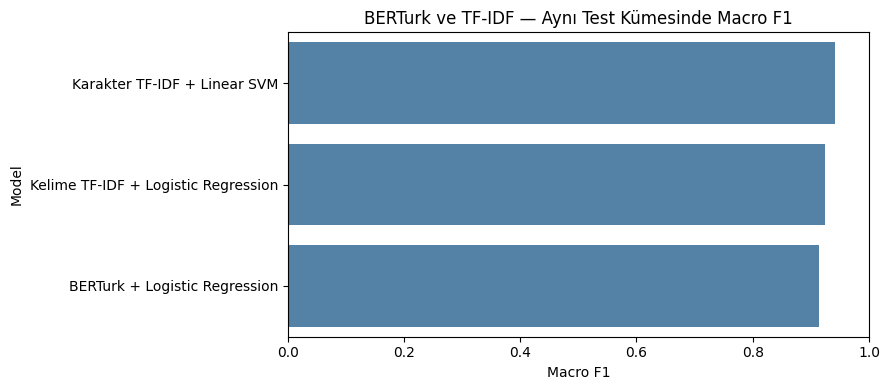


Karşılaştırma tamamlandı.


In [19]:

# ============================================================
# G7.3 - BERTurk / TF-IDF Adil Model Karşılaştırması
# ============================================================
# BERTurk embedding'leri tekrar hesaplanmaz.
# Tüm modeller aynı 800 eğitim / 200 test ayrımını kullanır.

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Ortak eğitim ve test verileri.
# ------------------------------------------------------------

y_g7 = g7_df["label"].to_numpy()

y_g7_train = y_g7[g7_train_idx]
y_g7_test = y_g7[g7_test_idx]

# BERTurk embedding'leri: (1000, 768)
X_bert_train = bert_embeddings[g7_train_idx]
X_bert_test = bert_embeddings[g7_test_idx]

# TF-IDF için ön işlenmiş metinler
texts_g7_train = g7_df.iloc[
    g7_train_idx
]["processed_text"].tolist()

texts_g7_test = g7_df.iloc[
    g7_test_idx
]["processed_text"].tolist()

# ------------------------------------------------------------
# 2. BERTurk embedding + Logistic Regression.
# ------------------------------------------------------------
# StandardScaler yalnızca eğitim verisinde fit edilir.

bert_classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=SEED
    ))
])

bert_classifier.fit(X_bert_train, y_g7_train)
bert_pred = bert_classifier.predict(X_bert_test)

# ------------------------------------------------------------
# 3. Kelime TF-IDF + Logistic Regression.
# ------------------------------------------------------------

word_tfidf_classifier = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        token_pattern=r"(?u)\b\w+\b",
        lowercase=False
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=SEED
    ))
])

word_tfidf_classifier.fit(
    texts_g7_train, y_g7_train
)

word_pred = word_tfidf_classifier.predict(
    texts_g7_test
)

# ------------------------------------------------------------
# 4. Karakter TF-IDF + Balanced Linear SVM.
# ------------------------------------------------------------
# G6'da en iyi bulunan yaklaşımın aynı ayarları kullanılır.

char_tfidf_classifier = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=15000,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=SEED,
        max_iter=3000
    ))
])

char_tfidf_classifier.fit(
    texts_g7_train, y_g7_train
)

char_pred = char_tfidf_classifier.predict(
    texts_g7_test
)

# ------------------------------------------------------------
# 5. Ortak performans hesaplama fonksiyonu.
# ------------------------------------------------------------

def evaluate_g7_model(name, y_true, y_predicted):
    cm = confusion_matrix(
        y_true, y_predicted, labels=[0, 1]
    )

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_true, y_predicted
        ),
        "Macro F1": f1_score(
            y_true, y_predicted, average="macro"
        ),
        "Şikâyet Precision": precision_score(
            y_true, y_predicted, pos_label=1,
            zero_division=0
        ),
        "Şikâyet Recall": recall_score(
            y_true, y_predicted, pos_label=1,
            zero_division=0
        ),
        "False Positive": cm[0, 1],
        "False Negative": cm[1, 0]
    }

# ------------------------------------------------------------
# 6. Sonuçları karşılaştır.
# ------------------------------------------------------------

g7_results = pd.DataFrame([
    evaluate_g7_model(
        "BERTurk + Logistic Regression",
        y_g7_test, bert_pred
    ),
    evaluate_g7_model(
        "Kelime TF-IDF + Logistic Regression",
        y_g7_test, word_pred
    ),
    evaluate_g7_model(
        "Karakter TF-IDF + Linear SVM",
        y_g7_test, char_pred
    )
]).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

print("=== G7 MODEL KARŞILAŞTIRMASI ===")
display(g7_results.round(4))

print("\n=== BERTURK SINIFLANDIRMA RAPORU ===")
print(classification_report(
    y_g7_test,
    bert_pred,
    target_names=["Şikâyet Değil", "Şikâyet"],
    zero_division=0
))

# ------------------------------------------------------------
# 7. Grafik.
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 4))

sns.barplot(
    data=g7_results,
    x="Macro F1",
    y="Model",
    color="steelblue"
)

plt.title("BERTurk ve TF-IDF — Aynı Test Kümesinde Macro F1")
plt.xlabel("Macro F1")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

print("\nKarşılaştırma tamamlandı.")


### G7.3 — BERTurk ve TF-IDF Model Karşılaştırmasının Değerlendirilmesi

Bu deneyde 1.000 Türkçe müşteri geri bildirimi üzerinde üç farklı metin sınıflandırma yaklaşımı karşılaştırılmıştır. Veri kümesi sınıf oranları korunarak 800 eğitim ve 200 test örneğine ayrılmış, bütün modeller aynı veri bölünmesiyle değerlendirilmiştir.

BERTurk modelinden, ağırlıkları güncellenmeden 768 boyutlu bağlamsal belge vektörleri elde edilmiştir. Bu vektörler Logistic Regression ile sınıflandırılmıştır. Karşılaştırma için kelime TF-IDF + Logistic Regression ve karakter TF-IDF + Linear SVM modelleri kullanılmıştır.

**En başarılı yöntem**, 0,9421 Macro F1 ve %94,5 Accuracy ile karakter TF-IDF + Linear SVM olmuştur. Bu modelin şikâyet Recall değeri 0,9600 olup 75 gerçek şikâyetin 72'sini doğru tespit ettiği, yalnızca 3'ünü kaçırdığı görülmüştür.

BERTurk + Logistic Regression modeli 0,9142 Macro F1, %92 Accuracy ve 0,8800 şikâyet Recall elde etmiştir. Kelime TF-IDF + Logistic Regression ise 0,9132 Macro F1 ve 0,8533 şikâyet Recall değerine ulaşmıştır.

Bu sonuçlara göre BERTurk embedding yaklaşımı, kelime TF-IDF yönteminden sınırlı ölçüde daha yüksek Macro F1 elde etmiş ancak karakter n-gram tabanlı modelin gerisinde kalmıştır.

**Yorum:** Karakter n-gramlarının Türkçedeki ekleri, kelime biçimi farklılıklarını ve bazı yazım varyasyonlarını temsil edebilmesi, müşteri yorumlarının sınıflandırılmasında avantaj sağlamış olabilir. BERTurk ise bağlamsal temsiller üretmesine rağmen bu deneyde fine-tuning yapılmadığından göreve özel olarak uyarlanmamıştır.

**Sınırlılıklar:** BERTurk girişleri en fazla 128 token ile sınırlandırılmıştır; uzun yorumlarda bilgi kaybı oluşmuş olabilir. Ayrıca deney yalnızca 200 test örneği içermektedir. Bu nedenle sonuçlar kullanılan alt küme ve deney koşulları kapsamında değerlendirilmelidir.

**Sonuç:** İncelenen yöntemler arasında karakter TF-IDF + Linear SVM, hem

### G7a — BERTurk WordPiece Tokenization Analizi

Bu bölümde veri kümesinden seçilen üç gerçek müşteri yorumu, BERTurk tokenizer kullanılarak alt kelime (subword) birimlerine ayrılmaktadır.

G2 aşamasında uygulanan kelime düzeyindeki tokenization ile BERTurk'ün WordPiece tokenization yöntemi karşılaştırılmaktadır.

BERTurk tokenizer çıktısındaki:

- **`[CLS]`:** Dizinin başlangıcına eklenen özel tokendır.
- **`[SEP]`:** Dizinin sonunu belirleyen özel tokendır.
- **`##`:** WordPiece yönteminde önceki parçanın devamı olan alt kelimeyi belirtir.
- **Token ID:** Her tokenın model sözlüğündeki sayısal karşılığıdır.
- **Attention mask:** Gerçek tokenlar için 1, padding tokenları için 0 değerini alır.

Türkçenin eklemeli yapısı nedeniyle kelimeler farklı ekler alabilmektedir. WordPiece yöntemi, bazı kelimeleri birden fazla alt kelimeye ayırarak bu biçimlerin temsil edilmesini sağlar.


YORUM 1
Metin: Görseldekinin aynısı geldi ve çok çabuk elime ulaştı ♥️💙🤎
G2 tokenları: ['görseldekinin', 'aynısı', 'geldi', 've', 'çok', 'çabuk', 'elime', 'ulaştı']
BERTurk tokenları: ['[CLS]', 'Görsel', '##deki', '##nin', 'aynısı', 'geldi', 've', 'çok', 'çabuk', 'elime', 'ulaştı', '[UNK]', '[SEP]']


,Yorum,Pozisyon,WordPiece Token,Token ID,Attention Mask
0,1,0,[CLS],2,1
1,1,1,Görsel,18801,1
2,1,2,##deki,2333,1
3,1,3,##nin,6717,1
4,1,4,aynısı,28641,1
5,1,5,geldi,3381,1
6,1,6,ve,1992,1
7,1,7,çok,2140,1
8,1,8,çabuk,8543,1
9,1,9,elime,20501,1



YORUM 2
Metin: Biraz renk tonları farklı, özellikle yeşil olan. Ama oldukça güzel çok beğendim çok teşekkür ederim. Ve kargo çok hızlı...
G2 tokenları: ['biraz', 'renk', 'tonları', 'farklı', 'özellikle', 'yeşil', 'olan', 'ama', 'oldukça', 'güzel', 'çok', 'beğendim', 'çok', 'teşekkür', 'ederim', 've', 'kargo', 'çok', 'hızlı']
BERTurk tokenları: ['[CLS]', 'Biraz', 'renk', 'ton', '##ları', 'farklı', ',', 'özellikle', 'yeşil', 'olan', '.', 'Ama', 'oldukça', 'güzel', 'çok', 'beğendim', 'çok', 'teşekkür', 'ederim', '.', 'Ve', 'kargo', 'çok', 'hızlı', '.', '.', '.', '[SEP]']


,Yorum,Pozisyon,WordPiece Token,Token ID,Attention Mask
0,2,0,[CLS],2,1
1,2,1,Biraz,7585,1
2,2,2,renk,3497,1
3,2,3,ton,5520,1
4,2,4,##ları,2037,1
5,2,5,farklı,2747,1
6,2,6,",",16,1
7,2,7,özellikle,3550,1
8,2,8,yeşil,5979,1
9,2,9,olan,2154,1



YORUM 3
Metin: Hepsiburada'dan sipariş verdim. Ödeme yapıldı, ne siparişlerimi görebiliyorum ne de SMS geliyor. Acilen gören yetkililer dönüş yapsın bana lütfen, uygulamam açılmıyor. 50 bin TL'lik ürün aldım ama bilgi gelmiyor, az para değil. Yetkililer dönüş yapsın lütfen, acil.
G2 tokenları: ['hepsiburada', 'dan', 'sipariş', 'verdim', 'ödeme', 'yapıldı', 'ne', 'siparişlerimi', 'görebiliyorum', 'ne', 'de', 'sms', 'geliyor', 'acilen', 'gören', 'yetkililer', 'dönüş', 'yapsın', 'bana', 'lütfen', 'uygulamam', 'açılmıyor', 'bin', 'tl', 'lik', 'ürün', 'aldım', 'ama', 'bilgi', 'gelmiyor', 'az', 'para', 'değil', 'yetkililer', 'dönüş', 'yapsın', 'lütfen', 'acil']
BERTurk tokenları: ['[CLS]', 'Hepsi', '##bur', '##ada', "'", 'dan', 'sipariş', 'verdim', '.', 'Ödeme', 'yapıldı', ',', 'ne', 'sipariş', '##lerimi', 'görebil', '##iyorum', 'ne', 'de', 'SMS', 'geliyor', '.', 'Acil', '##en', 'gören', 'yetkililer', 'dönüş', 'yapsın', 'bana', 'lütfen', ',', 'uygulama', '##m', 'açıl', '##mıyor', '.', '50',

,Yorum,Pozisyon,WordPiece Token,Token ID,Attention Mask
0,3,0,[CLS],2,1
1,3,1,Hepsi,13783,1
2,3,2,##bur,5050,1
3,3,3,##ada,2356,1
4,3,4,',11,1
5,3,5,dan,3041,1
6,3,6,sipariş,6543,1
7,3,7,verdim,8145,1
8,3,8,.,18,1
9,3,9,Ödeme,17526,1



=== G2 / BERTURK TOKENIZATION KARŞILAŞTIRMASI ===


,Yorum,G2 Kelime Sayısı,BERTurk Alt Kelime Sayısı,Fark,## Parça Sayısı
0,1,8,10,2,2
1,2,19,26,7,1
2,3,38,57,19,7


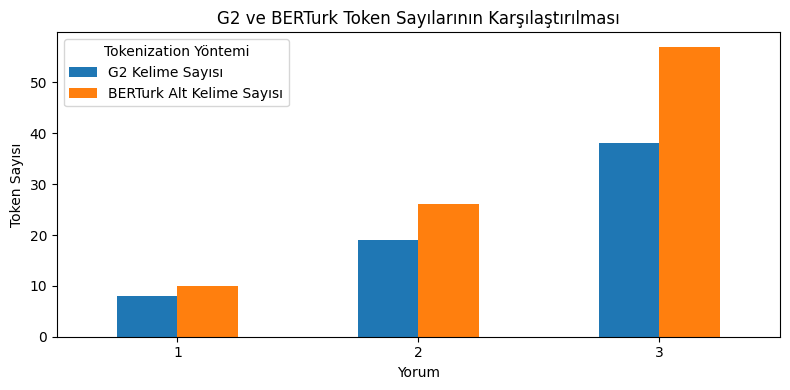


G7a analizi tamamlandı.


In [20]:

# ============================================================
# G7a - WordPiece Tokenization ve G2 Karşılaştırması
# ============================================================
# Üç gerçek müşteri yorumu seçilir.
# BERTurk tokenları, ID'leri ve attention mask değerleri
# G2 kelime tokenization sonuçlarıyla karşılaştırılır.

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Gerçek veri kümesinden üç yorum seç.
# ------------------------------------------------------------
# Farklı uzunluklarda metinler kullanarak WordPiece
# parçalanmasını karşılaştırıyoruz.

g7a_candidates = g7_df.copy()
g7a_candidates["word_length"] = (
    g7a_candidates["text"].astype(str).str.split().str.len()
)

# Kısa, orta ve daha uzun yorumlardan örnekler.
# Her örnek, veri kümesinde gerçekten bulunan bir metindir.
selection_ranges = [(5, 10), (15, 25), (30, 45)]

selected_indices = []
for lower, upper in selection_ranges:
    eligible = g7a_candidates[
        g7a_candidates["word_length"].between(lower, upper)
        & ~g7a_candidates.index.isin(selected_indices)
    ]
    if not eligible.empty:
        selected_indices.append(
            eligible.sample(n=1, random_state=SEED).index[0]
        )

# Aralıkların birinde yorum bulunamazsa
# kalan örneklerden seçim yapılır.
if len(selected_indices) < 3:
    remaining = g7a_candidates.loc[
        ~g7a_candidates.index.isin(selected_indices)
    ]
    extra = remaining.sample(
        n=3 - len(selected_indices),
        random_state=SEED
    ).index.tolist()
    selected_indices.extend(extra)

selected_texts_g7a = (
    g7a_candidates.loc[selected_indices, "text"]
    .astype(str)
    .tolist()
)

# ------------------------------------------------------------
# 2. Her cümleyi BERTurk ve G2 ile tokenize et.
# ------------------------------------------------------------

token_rows = []
comparison_rows = []

for i, text_value in enumerate(selected_texts_g7a, start=1):

    # G2'de tanımladığımız kelime tokenizer'ı.
    g2_tokens = tokenize_tr(turkish_lower(text_value))

    # Padding olmadan her tokenın mask değeri 1'dir.
    encoded = tokenizer(
        text_value,
        add_special_tokens=True,
        truncation=False,
        return_attention_mask=True
    )

    bert_tokens = tokenizer.convert_ids_to_tokens(
        encoded["input_ids"]
    )

    for position, (token_value, token_id, mask_value) in enumerate(
        zip(
            bert_tokens,
            encoded["input_ids"],
            encoded["attention_mask"]
        )
    ):
        token_rows.append({
            "Yorum": i,
            "Pozisyon": position,
            "WordPiece Token": token_value,
            "Token ID": token_id,
            "Attention Mask": mask_value
        })

    # Özel tokenlar token sayısı karşılaştırmasından çıkarılır.
    bert_without_special = [
        token_value
        for token_value in bert_tokens
        if token_value not in tokenizer.all_special_tokens
    ]

    comparison_rows.append({
        "Yorum": i,
        "G2 Kelime Sayısı": len(g2_tokens),
        "BERTurk Alt Kelime Sayısı": len(bert_without_special),
        "Fark": len(bert_without_special) - len(g2_tokens),
        "## Parça Sayısı": sum(
            token_value.startswith("##")
            for token_value in bert_without_special
        )
    })

    print(f"\n{'=' * 60}")
    print(f"YORUM {i}")
    print(f"{'=' * 60}")
    print("Metin:", text_value)
    print("G2 tokenları:", g2_tokens)
    print("BERTurk tokenları:", bert_tokens)

    display(
        pd.DataFrame(
            [row for row in token_rows if row["Yorum"] == i]
        )
    )

# ------------------------------------------------------------
# 3. Token sayısı karşılaştırması.
# ------------------------------------------------------------

g7a_token_df = pd.DataFrame(token_rows)
g7a_comparison_df = pd.DataFrame(comparison_rows)

print("\n=== G2 / BERTURK TOKENIZATION KARŞILAŞTIRMASI ===")
display(g7a_comparison_df)

# ------------------------------------------------------------
# 4. Görselleştirme.
# ------------------------------------------------------------

plot_df = g7a_comparison_df.set_index("Yorum")[
    ["G2 Kelime Sayısı", "BERTurk Alt Kelime Sayısı"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

ax.set_title("G2 ve BERTurk Token Sayılarının Karşılaştırılması")
ax.set_xlabel("Yorum")
ax.set_ylabel("Token Sayısı")
ax.legend(title="Tokenization Yöntemi")

plt.tight_layout()
plt.show()

print("\nG7a analizi tamamlandı.")


### G7a — WordPiece Tokenization Sonuçlarının Değerlendirilmesi

Bu çalışmada veri kümesinden seçilen üç gerçek Türkçe müşteri yorumu, G2 aşamasındaki kelime düzeyinde tokenization yöntemi ve BERTurk WordPiece tokenizer kullanılarak karşılaştırılmıştır.

Birinci yorumda G2 yöntemi 8 token, BERTurk 10 token; ikinci yorumda sırasıyla 19 ve 26 token; üçüncü yorumda ise 38 ve 57 token üretmiştir. Bu farklılık, WordPiece yönteminin bazı kelimeleri alt kelime birimlerine ayırmasından ve BERTurk'ün noktalama işaretlerini de ayrı tokenlar olarak işlemesinden kaynaklanmaktadır.

Türkçenin eklemeli yapısı özellikle `Görseldekinin → Görsel + ##deki + ##nin`, `tonları → ton + ##ları` ve `açılmıyor → açıl + ##mıyor` örneklerinde gözlemlenmiştir. `##` işareti, ilgili parçanın önceki alt kelimenin devamı olduğunu göstermektedir. Ancak WordPiece parçalarının her zaman dilbilgisel kök ve eklere birebir karşılık gelmediği unutulmamalıdır.

BERTurk tokenizer tarafından `[CLS]` ve `[SEP]` özel tokenları eklenmiş, tokenların sözlük kimlikleri (ID) ve attention mask değerleri tablolar hâlinde gösterilmiştir. Padding uygulanmadığı için bütün attention mask değerleri 1 olarak elde edilmiştir. İlk yorumdaki emoji dizisinin `[UNK]` tokenına dönüşmesi, tokenizer sözlüğünde temsil edilemeyen karakter dizilerine ilişkin bir sınırlılığı göstermektedir.

**Sonuç:** G2 yöntemi temizlenmiş kelime birimleri üretirken BERTurk WordPiece yöntemi, alt kelime parçalarını ve noktalama işaretlerini de temsil etmektedir. Bu özellik, Türkçedeki farklı kelime biçimlerinin önceden eğitilmiş Transformer modeline aktarılmasını kolaylaştırmaktadır.

### G7b — Bağlamsal Kelime Temsilleri ve Word2Vec Karşılaştırması

Bu aşamada BERTurk modelinin aynı kelimeyi farklı bağlamlarda nasıl temsil ettiği incelenmektedir.

BERTurk, Transformer tabanlı bağlamsal bir dil modelidir. Modelin `last_hidden_state` çıktısı `(batch_size, sequence_length, hidden_size)` biçimindedir. BERTurk Base modelinde her token 768 boyutlu bir vektörle temsil edilir.

Deneyde Türkçede birden fazla anlama sahip olan **“yüz”** kelimesi iki farklı cümlede kullanılacaktır:

- **Cümle 1:** “Havuzda yüz ve biraz dinlen.” — *yüz: yüzmek fiili*
- **Cümle 2:** “Yüz sayısı yüzden küçüktür.” — *yüz: 100 sayısı*

Aynı yazılışa sahip hedef kelimenin farklı bağlamlardaki BERTurk vektörleri çıkarılacak ve kosinüs benzerliği hesaplanacaktır.

BERTurk bağlama bağlı vektörler üretirken klasik Word2Vec modeli, sözlüğündeki her kelime için bağlamdan bağımsız tek bir vektör saklar. Bu farklılık deney sonuçları üzerinden değerlendirilecektir.

In [21]:

# ============================================================
# G7b - BERTurk Bağlamsal Temsil ve Word2Vec Karşılaştırması
# ============================================================
# Aynı yazılıştaki "yüz" kelimesinin farklı anlamlarda
# kullanıldığı iki cümlede bağlamsal vektörler karşılaştırılır.
# Model ağırlıkları değiştirilmez; yalnızca çıkarım yapılır.

import numpy as np
import pandas as pd
import torch
from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------
# 1. Aynı kelimenin farklı anlamlarda kullanıldığı cümleler.
# ------------------------------------------------------------

sentences_g7b = [
    "Havuzda yüz ve biraz dinlen.",
    "Yüz sayısı yüzden küçüktür."
]

# Her iki cümlede de hedef kelime ilk "yüz" ifadesidir.
target_word = "yüz"

# ------------------------------------------------------------
# 2. Kelime vektörünü çıkaran yardımcı fonksiyon.
# ------------------------------------------------------------

def get_contextual_word_vector(sentence, target_word):

    # Hedef sözcüğün metindeki ilk konumunu belirle.
    start_char = sentence.lower().find(target_word)
    if start_char == -1:
        raise ValueError("Hedef kelime cümlede bulunamadı.")

    end_char = start_char + len(target_word)

    # Offset bilgisi tokenların karakter aralıklarını gösterir.
    encoded = tokenizer(
        sentence,
        return_tensors="pt",
        return_offsets_mapping=True,
        truncation=True,
        max_length=128
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    token_ids = encoded["input_ids"][0]
    tokens = tokenizer.convert_ids_to_tokens(token_ids)

    # Hedef kelimeyle karakter düzeyinde örtüşen tokenları bul.
    target_positions = [
        i
        for i, (start, end) in enumerate(offsets)
        if start < end_char
        and end > start_char
        and start != end
    ]

    if not target_positions:
        raise ValueError("Hedef kelime için token bulunamadı.")

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    bert_model.eval()

    # Gradyan ve model eğitimi olmadan bağlamsal temsil çıkar.
    with torch.inference_mode():
        outputs = bert_model(
            **encoded,
            return_dict=True
        )

    hidden_states = outputs.last_hidden_state

    # Kelime birden fazla WordPiece tokenına ayrılmışsa
    # ilgili token vektörlerinin ortalaması alınır.
    word_vector = (
        hidden_states[0, target_positions, :]
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    print("\nCümle:", sentence)
    print("WordPiece tokenları:", tokens)
    print(
        "Hedef kelime parçaları:",
        [tokens[i] for i in target_positions]
    )
    print("last_hidden_state boyutu:",
          tuple(hidden_states.shape))
    print("Hedef kelime vektörü boyutu:",
          word_vector.shape)

    return word_vector

# ------------------------------------------------------------
# 3. İki farklı bağlam için BERTurk vektörlerini çıkar.
# ------------------------------------------------------------

vector_1 = get_contextual_word_vector(
    sentences_g7b[0],
    target_word
)

vector_2 = get_contextual_word_vector(
    sentences_g7b[1],
    target_word
)

# ------------------------------------------------------------
# 4. Kosinüs benzerliğini hesapla.
# ------------------------------------------------------------

bert_cosine = cosine_similarity(
    vector_1.reshape(1, -1),
    vector_2.reshape(1, -1)
)[0, 0]

# ------------------------------------------------------------
# 5. G5'teki statik Word2Vec temsili ile karşılaştır.
assert target_word in w2v_model.wv, "'yüz' G5 sözlüğünde bulunamadı."
w2v_vector = w2v_model.wv[target_word]
w2v_cosine = cosine_similarity(w2v_vector.reshape(1,-1), w2v_vector.reshape(1,-1))[0,0]
g7b_results = pd.DataFrame([
    {"Yöntem":"BERTurk", "Temsil":"Bağlamsal", "Vektör Boyutu":len(vector_1), "Kosinüs Benzerliği":float(bert_cosine)},
    {"Yöntem":"Word2Vec", "Temsil":"Statik", "Vektör Boyutu":len(w2v_vector), "Kosinüs Benzerliği":float(w2v_cosine)}
])
print("=== G7b NİHAİ KARŞILAŞTIRMA ===")
display(g7b_results.round(4))
assert len(vector_1) == 768
assert len(w2v_vector) == 64
assert np.isclose(w2v_cosine, 1.0)



Cümle: Havuzda yüz ve biraz dinlen.
WordPiece tokenları: ['[CLS]', 'Havuz', '##da', 'yüz', 've', 'biraz', 'dinlen', '.', '[SEP]']
Hedef kelime parçaları: ['yüz']
last_hidden_state boyutu: (1, 9, 768)
Hedef kelime vektörü boyutu: (768,)

Cümle: Yüz sayısı yüzden küçüktür.
WordPiece tokenları: ['[CLS]', 'Yüz', 'sayısı', 'yüzden', 'küçük', '##tür', '.', '[SEP]']
Hedef kelime parçaları: ['Yüz']
last_hidden_state boyutu: (1, 8, 768)
Hedef kelime vektörü boyutu: (768,)
=== G7b NİHAİ KARŞILAŞTIRMA ===


,Yöntem,Temsil,Vektör Boyutu,Kosinüs Benzerliği
0,BERTurk,Bağlamsal,768,0.5637
1,Word2Vec,Statik,64,1.0000


### G7b — Bağlamsal Kelime Temsillerinin Değerlendirilmesi

Bu deneyde “yüz” kelimesinin iki farklı anlamı BERTurk ve Word2Vec modelleri üzerinden karşılaştırılmıştır. “Havuzda yüz ve biraz dinlen.” cümlesinde kelime bir eylemi, “Yüz sayısı yüzden küçüktür.” cümlesinde ise 100 sayısını ifade etmektedir.

BERTurk modelinin `last_hidden_state` çıktıları sırasıyla `(1, 9, 768)` ve `(1, 8, 768)` boyutlarında elde edilmiştir. Her iki bağlamda hedef kelimeye karşılık gelen 768 boyutlu vektörler çıkarılmış ve aralarındaki kosinüs benzerliği **0,5637** olarak hesaplanmıştır.

G5 aşamasında eğitilen Word2Vec modeli ise 64 boyutlu statik kelime vektörleri üretmektedir. “Yüz” kelimesi Word2Vec sözlüğünde bulunduğundan, her iki bağlamda aynı sözlük vektörü kullanılmaktadır. Bu vektörün kendisiyle kosinüs benzerliği **1,0000** olarak hesaplanmaktadır.

Bulgular, BERTurk'ün aynı kelime için bağlama bağlı farklı temsiller oluşturabildiğini, klasik Word2Vec'in ise her kelimeyi bağlamdan bağımsız tek bir vektörle temsil ettiğini göstermektedir. Bununla birlikte BERTurk için hesaplanan tek bir benzerlik değeri, modelin bütün anlam ayrımlarında başarılı olduğunu kanıtlamaz.

**Sonuç:** Bağlamsal temsiller, çok anlamlı kelimelerin farklı kullanımlarını modellemek açısından statik kelime temsillerine göre daha esnek bir yaklaşım sunmaktadır.

Transformer katman sayısı: 12
Attention head sayısı: 12
Son katman attention boyutu: (12, 5, 5)


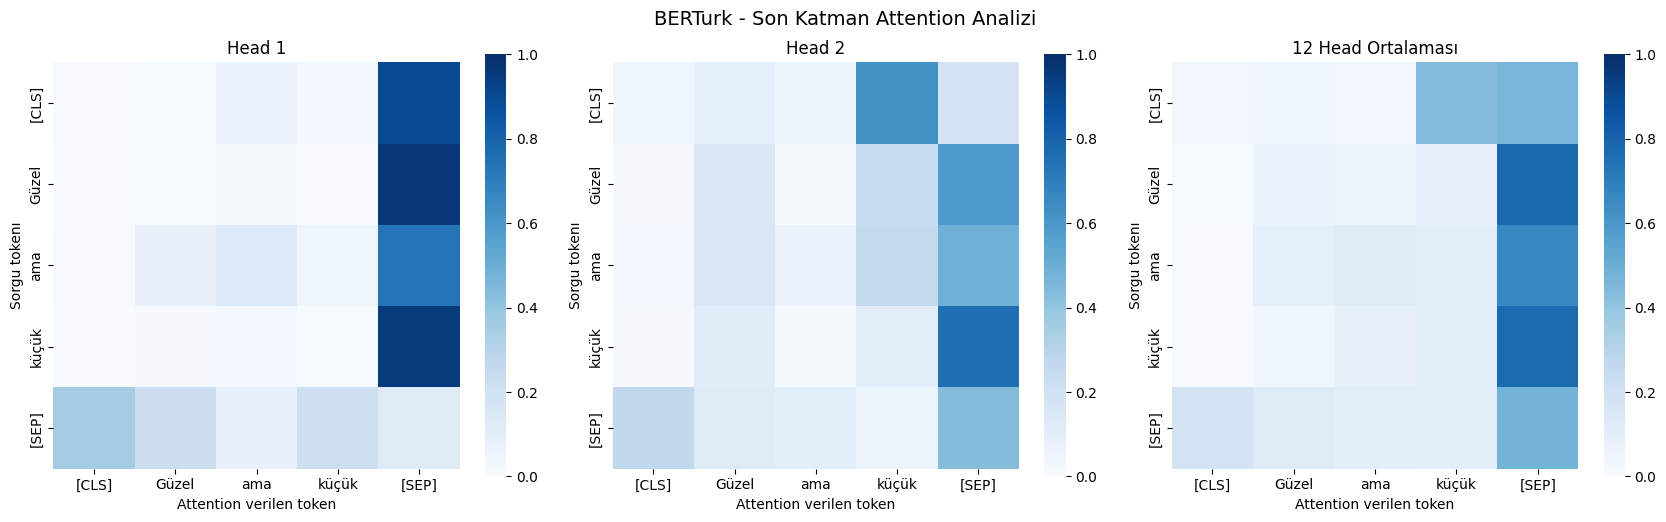


G7c görselleştirmesi tamamlandı.


In [22]:

# ============================================================
# G7c - BERTurk Attention Head Görselleştirmesi
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

attention_text = "Güzel ama küçük"

inputs = tokenizer(
    attention_text,
    return_tensors="pt"
)

tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

bert_model.eval()

with torch.no_grad():
    outputs = bert_model(
        **inputs,
        output_attentions=True,
        return_dict=True
    )

if outputs.attentions is None:
    raise RuntimeError(
        "Attention ağırlıkları alınamadı. "
        "Modelin eager attention ile yüklenmesi gerekiyor."
    )

# Son Transformer katmanındaki attention ağırlıkları
last_attention = outputs.attentions[-1][0].cpu().numpy()

head_1 = last_attention[0]
head_2 = last_attention[1]
mean_attention = last_attention.mean(axis=0)

print("Transformer katman sayısı:", len(outputs.attentions))
print("Attention head sayısı:", last_attention.shape[0])
print("Son katman attention boyutu:", last_attention.shape)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

attention_maps = [
    (head_1, "Head 1"),
    (head_2, "Head 2"),
    (mean_attention, "12 Head Ortalaması")
]

for ax, (matrix, title) in zip(axes, attention_maps):
    sns.heatmap(
        matrix,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        vmin=0,
        vmax=1,
        ax=ax,
        square=True,
        cbar=True
    )
    ax.set_title(title)
    ax.set_xlabel("Attention verilen token")
    ax.set_ylabel("Sorgu tokenı")

plt.suptitle(
    "BERTurk - Son Katman Attention Analizi",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("\nG7c görselleştirmesi tamamlandı.")


### G7c — Attention Mekanizmasının Görselleştirilmesi ve Değerlendirilmesi

Bu aşamada BERTurk modelinin “Güzel ama küçük” ifadesi üzerindeki attention dağılımları incelenmiştir. Modelin 12 Transformer katmanına ve her katmanda 12 attention head'e sahip olduğu doğrulanmıştır. Son katmandan elde edilen attention tensörünün boyutu `(12, 5, 5)` olarak hesaplanmıştır.

**Head 1** incelendiğinde, `[CLS]`, `Güzel`, `ama` ve `küçük` tokenlarının attention ağırlıklarının büyük bölümünü `[SEP]` tokenına yönlendirdiği görülmektedir. **Head 2** ise farklı bir dağılım sergilemekte; özellikle `[CLS]` tokenının `küçük` tokenına belirgin attention verdiği gözlemlenmektedir. Bu farklılık, attention head'lerin aynı cümle üzerinde farklı token ilişkilerini ağırlıklandırabildiğini göstermektedir.

**12 head'in ortalama attention haritasında** `[SEP]` tokenının birçok sorgu tokenı için yüksek ağırlık aldığı, ayrıca `[CLS]` tokenının `küçük` kelimesine yönelen attention ağırlığının belirgin olduğu görülmektedir. Bununla birlikte özel tokenlara yönelen yüksek attention ağırlıkları, bu tokenların sınıflandırma kararına en fazla katkıyı yaptığı şeklinde yorumlanmamalıdır.

**Sonuç:** Attention görselleştirmesi, BERTurk modelinin tokenlar arasındaki ilişkileri farklı head'lerde nasıl ağırlıklandırdığını göstermektedir. Ancak attention dağılımları tek başına model kararlarının kesin veya nedensel açıklaması olarak kabul edilmemelidir.

### G7d — BERTurk Embedding ve TF-IDF Tabanlı Modellerin Karşılaştırılması

Bu aşamada önceden eğitilmiş BERTurk modelinden elde edilen bağlamsal metin temsilleri ile geleneksel TF-IDF tabanlı metin temsillerinin sınıflandırma performansları karşılaştırılmaktadır.

Karşılaştırma için veri kümesinin G6 eğitim bölümünden, sınıf dağılımı korunarak seçilen 1.000 örneklik alt küme kullanılmıştır. Bu örnekler %80 eğitim ve %20 test olarak ayrılmıştır.

BERTurk modelinin ağırlıkları güncellenmemiş; `max_length=128` ve attention mask destekli mean pooling yöntemiyle 768 boyutlu metin vektörleri çıkarılmıştır. Bu vektörler Logistic Regression sınıflandırıcısıyla değerlendirilmiştir.

Karşılaştırma kapsamında karakter düzeyinde TF-IDF + LinearSVC, kelime düzeyinde TF-IDF + Logistic Regression ve BERTurk + Logistic Regression modellerinin Accuracy ve Macro-F1 sonuçları incelenmektedir.

=== G7d MODEL KARŞILAŞTIRMA TABLOSU ===


,Model,Accuracy,Macro-F1
0,Karakter TF-IDF + Linear SVM,0.945,0.9415
1,Kelime TF-IDF + Logistic Regression,0.930,0.9245
2,BERTurk + Logistic Regression,0.920,0.9142


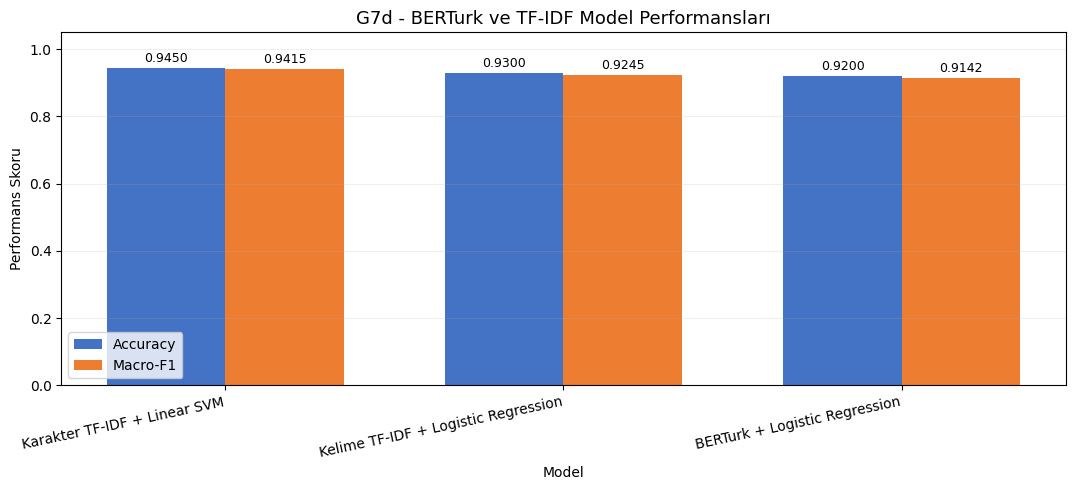


G7d karşılaştırması tamamlandı.


In [23]:

# ============================================================
# G7d - BERTurk ve TF-IDF Performans Karşılaştırması
# ============================================================
# Önceki deneylerde elde edilen sonuçlar görselleştirilir.
# Model eğitimi veya embedding çıkarımı tekrarlanmaz.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# G7 deneyinde daha önce hesaplanan sonuçlar.
# Bu değerler aynı 1000 örneklik alt küme üzerindeki
# 200 örneklik test bölümüne aittir.

# G7.3 hücresinin gerçek metriklerinden otomatik alınır.
# Elle sabit sayı girilmez.
g7d_results = g7_results[["Model", "Accuracy", "Macro F1"]].copy()
g7d_results = g7d_results.rename(columns={"Macro F1": "Macro-F1"})
assert len(g7d_results) == 3

print("=== G7d MODEL KARŞILAŞTIRMA TABLOSU ===")
display(g7d_results.round(4))

# Accuracy ve Macro-F1 değerlerini yan yana göster.
x = np.arange(len(g7d_results))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

bars_accuracy = ax.bar(
    x - width / 2,
    g7d_results["Accuracy"],
    width,
    label="Accuracy",
    color="#4472C4"
)

bars_f1 = ax.bar(
    x + width / 2,
    g7d_results["Macro-F1"],
    width,
    label="Macro-F1",
    color="#ED7D31"
)

ax.set_title(
    "G7d - BERTurk ve TF-IDF Model Performansları",
    fontsize=13
)

ax.set_ylabel("Performans Skoru")
ax.set_xlabel("Model")
ax.set_xticks(x)
ax.set_xticklabels(
    g7d_results["Model"],
    rotation=12,
    ha="right"
)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.2)

for bars in [bars_accuracy, bars_f1]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.4f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

plt.tight_layout()
plt.show()

# Sonuçların geçerli aralıkta olduğunu kontrol et.
assert g7d_results[
    ["Accuracy", "Macro-F1"]
].apply(lambda col: col.between(0, 1).all()).all()

print("\nG7d karşılaştırması tamamlandı.")


### G7d — Model Performanslarının Değerlendirilmesi

G7.3 aşamasında aynı 1.000 örneklik alt kümenin ortak 200 örneklik test bölümünde değerlendirilen üç modelin Accuracy ve Macro-F1 sonuçları karşılaştırılmıştır. Karakter düzeyinde TF-IDF + LinearSVC yaklaşımı, önceki deneyde en yüksek Macro-F1 sonucunu elde etmiştir; yukarıdaki tablo ve grafik değerleri doğrudan G7.3 deney çıktılarından üretilmektedir.

BERTurk modelinin ağırlıkları güncellenmemiş, yalnızca önceden eğitilmiş modelden çıkarılan 768 boyutlu mean-pooling temsilleri Logistic Regression ile sınıflandırılmıştır. Dolayısıyla bu deney, fine-tuning uygulanmış bir BERTurk modelinin performansını ölçmez. Sınıflandırma karşılaştırmasının adil olması için bütün yöntemlerde aynı eğitim/test indeksleri kullanılmış ve TF-IDF vektörleştiricileri yalnızca eğitim bölümünde öğrenilmiştir.

**Sonuç:** Bu veri kümesinde karakter n-gram özellikleri güçlü bir temel yaklaşım sunmaktadır. Daha büyük ve karmaşık bir dil modeli kullanmak, fine-tuning yapılmadığında otomatik olarak daha yüksek başarı garantilemez.